<a href="https://colab.research.google.com/github/davidlealo/sic_ia_2026/blob/main/ejercicios_profesor/sic2026_ia_clase08_nosupervisado_taller_PROFE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from sklearn.datasets import make_blobs, make_moons
import matplotlib.pyplot as plt

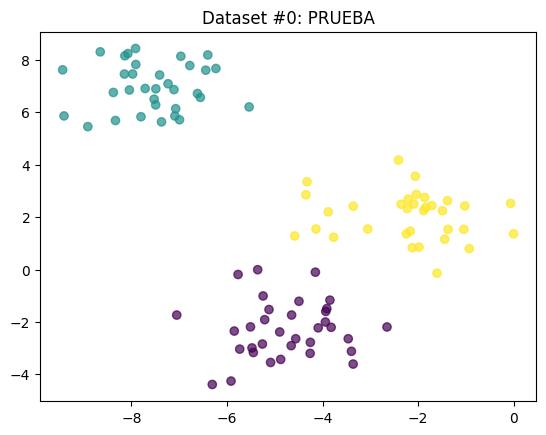

In [ ]:
X0, label0 = make_blobs(n_samples=100, n_features=2, centers=None, cluster_std=1.0, center_box=(-10.0, 10.0), shuffle=True, random_state=None, return_centers=False)
plt.scatter(X0[:, 0], X0[:, 1], c=label0, alpha=0.7)
plt.title('Dataset #0: PRUEBA')
plt.show()

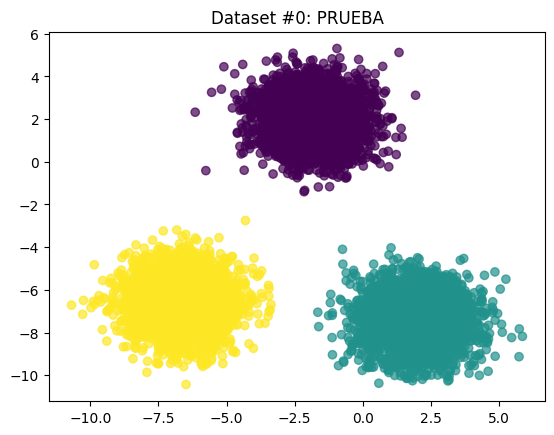

In [ ]:
X0, label0 = make_blobs(n_samples=10000, n_features=2, centers=None, cluster_std=1.0, center_box=(-10.0, 10.0), shuffle=True, random_state=None, return_centers=False)
plt.scatter(X0[:, 0], X0[:, 1], c=label0, alpha=0.7)
plt.title('Dataset #0: PRUEBA')
plt.show()

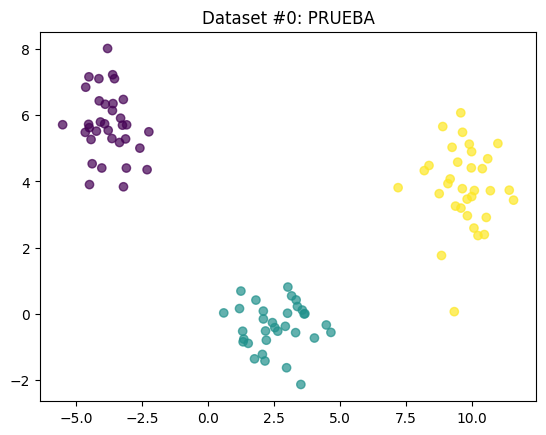

In [ ]:
X0, label0 = make_blobs(n_samples=100, n_features=4, centers=None, cluster_std=1.0, center_box=(-10.0, 10.0), shuffle=True, random_state=None, return_centers=False)
plt.scatter(X0[:, 0], X0[:, 1], c=label0, alpha=0.7)
plt.title('Dataset #0: PRUEBA')
plt.show()

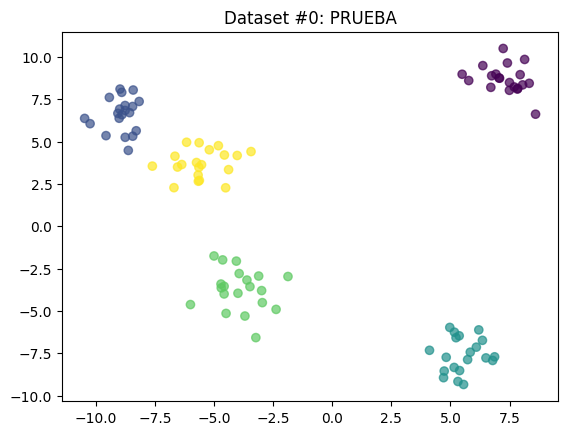

In [ ]:
X0, label0 = make_blobs(n_samples=100, n_features=2, centers=5, cluster_std=1.0, center_box=(-10.0, 10.0), shuffle=True, random_state=None, return_centers=False)
plt.scatter(X0[:, 0], X0[:, 1], c=label0, alpha=0.7)
plt.title('Dataset #0: PRUEBA')
plt.show()

In [ ]:
X0, label0 = make_blobs(n_samples=100, n_features=2, centers=5, cluster_std=1.0, center_box=(-10.0, 10.0), shuffle=True, random_state=None, return_centers=True)
plt.scatter(X0[:, 0], X0[:, 1], c=label0, alpha=0.7)
plt.title('Dataset #0: PRUEBA')
plt.show()

ValueError: too many values to unpack (expected 2)

El problema es el desempaquetado. Con `return_centers=True`, `make_blobs` devuelve **tres** valores en lugar de dos:

1. `X`: los puntos generados.
2. `y`: la etiqueta (cluster) de cada punto.
3. `centers`: las coordenadas de los centros de cada cluster, con forma `(n_centers, n_features)`.

Como estás recibiendo solo dos variables (`X0, label0`), Python lanza un error del tipo `ValueError: too many values to unpack (expected 2)`.

La solución es agregar una tercera variable. De paso puedes graficar los centros, que es justamente para lo que sirve ese parámetro:

```python
X0, label0, centers0 = make_blobs(n_samples=100, n_features=2, centers=5,
                                  cluster_std=1.0, center_box=(-10.0, 10.0),
                                  shuffle=True, random_state=None,
                                  return_centers=True)

plt.scatter(X0[:, 0], X0[:, 1], c=label0, alpha=0.7)
plt.scatter(centers0[:, 0], centers0[:, 1], c='red', marker='X', s=200, label='Centros')
plt.title('Dataset #0: PRUEBA')
plt.legend()
plt.show()
```

Los centros sirven sobre todo como "verdad de referencia" para evaluar un algoritmo de clustering. Por ejemplo, puedes comparar los centroides que encuentra K-Means con `centers0`. Si no los necesitas, puedes dejar `return_centers=False` (el valor por defecto).

Un detalle adicional: con `random_state=None` los datos cambian cada vez que corres la celda. Si quieres resultados reproducibles, fija un número, por ejemplo `random_state=42`.

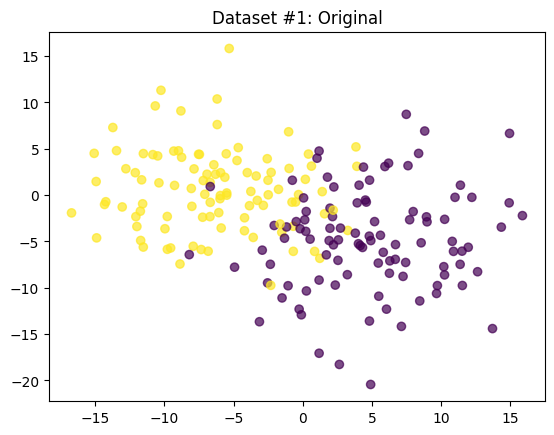

In [ ]:
X1, label1 = make_blobs(n_samples=200, n_features=2, centers=2, cluster_std=5, random_state=123)
plt.scatter(X1[:, 0], X1[:, 1], c=label1, alpha=0.7)
plt.title('Dataset #1: Original')
plt.show()

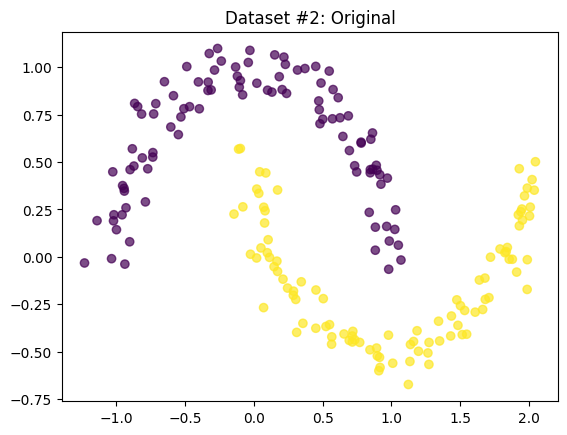

In [ ]:
X2, label2 = make_moons(n_samples=200, noise=0.08, random_state=123)
plt.scatter(X2[:, 0], X2[:, 1], c=label2, alpha=0.7)
plt.title('Dataset #2: Original')
plt.show()

In [ ]:
from sklearn.cluster import AgglomerativeClustering

# `sklearn.cluster.AgglomerativeClustering`: guía detallada de hiperparámetros

Referencia oficial: https://scikit-learn.org/stable/modules/generated/sklearn.cluster.AgglomerativeClustering.html (documentación de scikit-learn 1.9).

---

## 1. Qué hace el algoritmo

`AgglomerativeClustering` implementa clustering jerárquico **aglomerativo** (de abajo hacia arriba):

1. Cada observación comienza como un cluster propio. Con `n` muestras hay `n` clusters.
2. En cada paso se calculan las distancias entre todos los pares de clusters según un **criterio de enlace** (`linkage`).
3. Se fusionan los dos clusters más cercanos.
4. Se repite hasta que queda un solo cluster (árbol completo) o hasta cumplir una condición de parada (`n_clusters` o `distance_threshold`).

El resultado es un árbol binario llamado **dendrograma**. Cortar ese árbol a cierta altura entrega una partición plana de los datos.

Diferencias importantes frente a K-Means:

| Aspecto | K-Means | AgglomerativeClustering |
|---|---|---|
| Tipo | Particional, basado en centroides | Jerárquico |
| Determinismo | Depende de la inicialización (`random_state`) | Determinista (no tiene `random_state`) |
| Forma de clusters | Esféricos, de tamaño similar | Depende del `linkage`; `single` captura formas arbitrarias |
| Datos nuevos | Tiene `predict` | **No tiene `predict`**, solo `fit` y `fit_predict` |
| Costo | Aproximadamente lineal en `n` | Memoria O(n^2); tiempo entre O(n^2) y O(n^3) |
| Número de clusters | Obligatorio | Se puede reemplazar por un umbral de distancia |

---

## 2. Firma completa

```python
from sklearn.cluster import AgglomerativeClustering

AgglomerativeClustering(
    n_clusters=2,
    *,                      # todo lo que sigue debe pasarse por nombre
    metric="euclidean",
    memory=None,
    connectivity=None,
    compute_full_tree="auto",
    linkage="ward",
    distance_threshold=None,
    compute_distances=False,
)
```

El asterisco `*` indica que, salvo `n_clusters`, todos los parámetros son **solo por palabra clave**. `AgglomerativeClustering(3, "average")` falla; lo correcto es `AgglomerativeClustering(3, linkage="average")`.

---

## 3. Datos base para todos los ejemplos

```python
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_moons
from sklearn.cluster import AgglomerativeClustering

X, y_true, centers = make_blobs(
    n_samples=300, centers=4, cluster_std=0.8,
    random_state=42, return_centers=True
)

def graficar(X, labels, titulo, ax=None):
    ax = ax or plt.gca()
    ax.scatter(X[:, 0], X[:, 1], c=labels, cmap="tab10", s=15, alpha=0.8)
    ax.set_title(titulo)
```

---

## 4. Hiperparámetros

### 4.1 `n_clusters`

| Tipo | Valor por defecto |
|---|---|
| `int` o `None` | `2` |

Número de clusters que se quiere obtener. El algoritmo fusiona hasta que quedan exactamente `n_clusters` grupos.

**Regla clave:** debe ser `None` si se usa `distance_threshold`. Los dos mecanismos de parada son excluyentes.

**Variaciones**

| Valor | Efecto |
|---|---|
| `2` (defecto) | Divide los datos en dos grupos, aunque haya más estructura. Error común al olvidar ajustarlo. |
| Entero `k` | Corta el dendrograma de modo que queden `k` grupos. |
| `1` | Todo queda en un único cluster (válido, pero poco útil). |
| `n_samples` | Cada punto es su propio cluster. |
| `None` | Obligatorio cuando se define `distance_threshold`. |

**Ejemplo: efecto de distintos `k`**

```python
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, k in zip(axes, [2, 3, 4, 6]):
    modelo = AgglomerativeClustering(n_clusters=k)
    labels = modelo.fit_predict(X)
    graficar(X, labels, f"n_clusters={k}", ax)
plt.tight_layout()
plt.show()
```

Con `k=4` se recupera la estructura real. Con `k=2` se fusionan grupos reales; con `k=6` se parten grupos reales.

---

### 4.2 `metric`

| Tipo | Valor por defecto |
|---|---|
| `str` o `callable` | `"euclidean"` |

Métrica con la que se mide la distancia entre observaciones para calcular el enlace.

Valores aceptados: `"euclidean"`, `"l1"`, `"l2"`, `"manhattan"`, `"cosine"`, `"precomputed"`.

Nota de versiones: este parámetro se llamaba `affinity` hasta la versión 1.2. `affinity` fue eliminado en la 1.4, así que código antiguo con `affinity="cosine"` falla en versiones actuales. Hay que reemplazarlo por `metric="cosine"`.

**Significado de cada métrica**

| Métrica | Fórmula (entre `a` y `b`) | Cuándo usarla |
|---|---|---|
| `"euclidean"` / `"l2"` | raíz de la suma de (a_i - b_i)^2 | Datos continuos en escalas comparables. Son equivalentes. |
| `"manhattan"` / `"l1"` | suma de \|a_i - b_i\| | Más robusta a valores extremos en una dimensión; datos en cuadrícula. Son equivalentes. |
| `"cosine"` | 1 - cos(ángulo entre a y b) | Importa la dirección, no la magnitud: texto (TF-IDF), embeddings, perfiles. |
| `"precomputed"` | El usuario entrega la matriz de distancias | Distancias propias (edición, DTW, Jaccard, grafos). |
| `callable` | Función propia `f(a, b) -> float` | Métricas personalizadas. |

**Restricciones**

- Con `linkage="ward"` **solo** se aceptan `"euclidean"` y `"l2"`. Ward minimiza varianza, y la varianza es un concepto euclidiano.
- Con `"precomputed"`, `fit` recibe una matriz cuadrada de distancias `(n_samples, n_samples)`, no la matriz de atributos.
- Si `connectivity=None`, `linkage="single"` y la métrica no es `"precomputed"`, se puede usar cualquier métrica válida de `pairwise_distances` (por ejemplo `"chebyshev"` o `"minkowski"`).

**Ejemplo: comparar métricas (requiere un linkage distinto de ward)**

```python
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, m in zip(axes, ["euclidean", "manhattan", "cosine"]):
    modelo = AgglomerativeClustering(n_clusters=4, metric=m, linkage="average")
    graficar(X, modelo.fit_predict(X), f"metric={m}, linkage=average", ax)
plt.tight_layout()
plt.show()
```

Con datos en 2D centrados lejos del origen, `cosine` agrupa por ángulo respecto al origen, lo que produce "rebanadas" radiales en lugar de manchas. Esto ilustra que la métrica debe elegirse según el significado de los datos.

**Ejemplo: matriz precomputada**

```python
from sklearn.metrics import pairwise_distances

D = pairwise_distances(X, metric="manhattan")      # forma (300, 300)
modelo = AgglomerativeClustering(
    n_clusters=4, metric="precomputed", linkage="complete"
)
labels = modelo.fit_predict(D)                     # se pasa D, no X
```

**Ejemplo: métrica personalizada (callable)**

Detalle importante: en `AgglomerativeClustering` la función **no** recibe dos puntos `(a, b)` como en otros estimadores. Recibe la matriz `X` completa y debe devolver la matriz de distancias `(n_samples, n_samples)`. Escribirla como `f(a, b)` produce `TypeError: missing 1 required positional argument`.

```python
from sklearn.metrics import pairwise_distances

def distancia_ponderada(X):
    pesos = np.sqrt(np.array([1.0, 3.0]))   # el eje y pesa el triple
    return pairwise_distances(X * pesos, metric="euclidean")

modelo = AgglomerativeClustering(
    n_clusters=4, metric=distancia_ponderada, linkage="average"
)
labels = modelo.fit_predict(X)
```

Si la distancia que se tiene está definida entre pares de puntos, se puede envolver con `pairwise_distances(X, metric=f)`, aunque una función en Python puro es mucho más lenta que las métricas nativas. Para conjuntos grandes conviene calcular la matriz una vez y usar `"precomputed"`.

---

### 4.3 `linkage`

| Tipo | Valor por defecto |
|---|---|
| `{"ward", "complete", "average", "single"}` | `"ward"` |

Define **cómo se mide la distancia entre dos clusters** (no entre dos puntos). En cada paso se fusiona el par que minimiza este criterio. Es el hiperparámetro que más cambia el resultado.

Sea A y B dos clusters y d(a, b) la métrica entre puntos:

| Linkage | Distancia entre A y B | Comportamiento típico |
|---|---|---|
| `"ward"` | Aumento de la varianza intra-cluster al fusionar A y B | Clusters compactos y de tamaño parecido. Resultado similar a K-Means. Solo euclidiana. |
| `"complete"` (o máximo) | Máximo de d(a, b) entre todos los pares | Clusters compactos, sensible a outliers. Tiende a evitar clusters alargados. |
| `"average"` | Promedio de d(a, b) entre todos los pares | Punto intermedio. Funciona con cualquier métrica. |
| `"single"` | Mínimo de d(a, b) entre todos los pares | Detecta formas arbitrarias (cadenas, lunas). Sufre "efecto cadena": un puente de puntos une grupos distintos. Es el más rápido. |

**Ejemplo 1: blobs (estructura esférica)**

```python
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, link in zip(axes, ["ward", "complete", "average", "single"]):
    modelo = AgglomerativeClustering(n_clusters=4, linkage=link)
    graficar(X, modelo.fit_predict(X), f"linkage={link}", ax)
plt.tight_layout()
plt.show()
```

Con blobs bien separados, `ward`, `complete` y `average` aciertan. `single` puede dejar un cluster gigante y otros de pocos puntos si hay puntos intermedios.

**Ejemplo 2: lunas (estructura no convexa)**

```python
X_moons, _ = make_moons(n_samples=300, noise=0.05, random_state=0)

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, link in zip(axes, ["ward", "complete", "average", "single"]):
    modelo = AgglomerativeClustering(n_clusters=2, linkage=link)
    graficar(X_moons, modelo.fit_predict(X_moons), f"linkage={link}", ax)
plt.tight_layout()
plt.show()
```

Aquí ocurre lo contrario: solo `single` separa correctamente las dos lunas, porque sigue la cadena de vecinos más cercanos. Los demás cortan las lunas con una línea casi recta.

**Ejemplo 3: medir el efecto con una métrica externa**

```python
from sklearn.metrics import adjusted_rand_score

for link in ["ward", "complete", "average", "single"]:
    labels = AgglomerativeClustering(n_clusters=4, linkage=link).fit_predict(X)
    print(f"{link:>9}: ARI = {adjusted_rand_score(y_true, labels):.3f}")
```

El ARI (Adjusted Rand Index) vale 1 para coincidencia perfecta con las etiquetas reales y cerca de 0 para una asignación aleatoria.

---

### 4.4 `distance_threshold`

| Tipo | Valor por defecto |
|---|---|
| `float` o `None` | `None` |

Umbral de distancia de enlace: los clusters cuya distancia sea **mayor o igual** al umbral no se fusionan. En vez de fijar cuántos clusters se quieren, se fija **qué tan distintos** deben ser dos grupos para mantenerse separados. El número de clusters resultante se lee en `n_clusters_`.

**Reglas obligatorias**

- `n_clusters` debe ser `None`.
- `compute_full_tree` debe ser `True` (o `"auto"`, que en este caso equivale a `True`).
- Activar el umbral calcula automáticamente `distances_`, por lo que se puede graficar el dendrograma sin activar `compute_distances`.

**Variaciones**

| Valor | Efecto |
|---|---|
| `None` | Se usa `n_clusters`. |
| Umbral bajo | Pocas fusiones, muchos clusters. |
| Umbral alto | Muchas fusiones, pocos clusters. |
| `0` | Ninguna fusión: cada punto es un cluster. Útil para construir el árbol completo y graficarlo. |

La escala del umbral depende del `linkage`: en `ward` las distancias crecen mucho más rápido que en `single`, así que un mismo valor numérico produce resultados muy distintos.

**Ejemplo: barrido de umbrales**

```python
for t in [2, 5, 10, 20, 50]:
    modelo = AgglomerativeClustering(n_clusters=None, distance_threshold=t)
    modelo.fit(X)
    print(f"distance_threshold={t:>3} -> n_clusters_ = {modelo.n_clusters_}")
```

**Error frecuente**

```python
# FALLA: n_clusters vale 2 por defecto y choca con el umbral
AgglomerativeClustering(distance_threshold=10).fit(X)
# ValueError: Exactly one of n_clusters and distance_threshold has to be set...

# CORRECTO
AgglomerativeClustering(n_clusters=None, distance_threshold=10).fit(X)
```

---

### 4.5 `compute_distances`

| Tipo | Valor por defecto |
|---|---|
| `bool` | `False` |

Si es `True`, el modelo guarda en `distances_` la distancia a la que se produjo cada fusión, **aunque no se use `distance_threshold`**. Sirve principalmente para dibujar el dendrograma. Tiene un costo adicional de cómputo y memoria.

| Valor | Efecto |
|---|---|
| `False` | `distances_` no existe, salvo que se use `distance_threshold`. |
| `True` | `distances_` disponible siempre. |

**Ejemplo: dendrograma con `scipy`**

`scipy.cluster.hierarchy.dendrogram` espera una "matriz de enlace" con cuatro columnas: los dos nodos fusionados, la distancia y la cantidad de muestras del nuevo nodo. La siguiente función la construye a partir del modelo de scikit-learn:

```python
from scipy.cluster.hierarchy import dendrogram

def matriz_enlace(modelo):
    n = len(modelo.labels_)
    conteos = np.zeros(modelo.children_.shape[0])
    for i, (izq, der) in enumerate(modelo.children_):
        total = 0
        for hijo in (izq, der):
            total += 1 if hijo < n else conteos[hijo - n]
        conteos[i] = total
    return np.column_stack([modelo.children_, modelo.distances_, conteos]).astype(float)

modelo = AgglomerativeClustering(n_clusters=4, compute_distances=True).fit(X)

plt.figure(figsize=(12, 5))
dendrogram(matriz_enlace(modelo), truncate_mode="level", p=4)
plt.title("Dendrograma (ward), truncado a 4 niveles")
plt.xlabel("Índice de muestra o (tamaño del nodo)")
plt.ylabel("Distancia de fusión")
plt.show()
```

Lectura del dendrograma: los saltos verticales grandes indican fusiones entre grupos muy distintos. Una línea horizontal que cruce el salto más largo sugiere un buen número de clusters. Esa altura es un buen candidato para `distance_threshold`.

**Error frecuente**

```python
modelo = AgglomerativeClustering(n_clusters=4).fit(X)
modelo.distances_
# AttributeError: el atributo no existe porque compute_distances=False
```

---

### 4.6 `connectivity`

| Tipo | Valor por defecto |
|---|---|
| matriz (densa o dispersa), `callable` o `None` | `None` |

Restricción de vecindad: indica, para cada muestra, cuáles muestras se consideran vecinas. **Solo se pueden fusionar clusters que estén conectados** en ese grafo.

| Valor | Efecto |
|---|---|
| `None` | Clustering no estructurado: cualquier par de clusters puede fusionarse. |
| Matriz `(n_samples, n_samples)` | Grafo explícito de vecindad (por ejemplo, píxeles adyacentes de una imagen). |
| `callable` | Función que recibe `X` y devuelve la matriz (por ejemplo, un `kneighbors_graph` parametrizado). |

**Para qué sirve**

1. **Respetar estructura local:** obliga a que los clusters sigan la forma de los datos (variedades, rollos, lunas).
2. **Datos con estructura espacial:** segmentación de imágenes con `grid_to_graph`, donde un cluster debe ser una región contigua.
3. **Velocidad:** con un grafo disperso, el algoritmo evalúa muchos menos pares y escala mejor.

**Ejemplo: lunas con ward más conectividad**

```python
from sklearn.neighbors import kneighbors_graph

conn = kneighbors_graph(X_moons, n_neighbors=10, include_self=False)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sin = AgglomerativeClustering(n_clusters=2, linkage="ward").fit_predict(X_moons)
con = AgglomerativeClustering(
    n_clusters=2, linkage="ward", connectivity=conn
).fit_predict(X_moons)
graficar(X_moons, sin, "ward sin connectivity", axes[0])
graficar(X_moons, con, "ward con connectivity (k=10)", axes[1])
plt.tight_layout()
plt.show()
```

Con la restricción, ward deja de cortar las lunas por la mitad, porque no puede unir puntos que no son vecinos.

**Variación: conectividad como función**

```python
from functools import partial

conn_fn = partial(kneighbors_graph, n_neighbors=10, include_self=False)
modelo = AgglomerativeClustering(n_clusters=2, connectivity=conn_fn).fit(X_moons)
```

**Advertencias**

- Si el grafo tiene varias **componentes desconectadas**, el algoritmo no puede unirlas por sí solo. scikit-learn emite una advertencia y completa el grafo para poder terminar. El número de componentes queda en `n_connected_components_`.
- Un `n_neighbors` muy bajo fragmenta el grafo; uno muy alto anula el efecto de la restricción.
- Con `linkage="single"` y conectividad, el resultado puede volverse muy inestable.

---

### 4.7 `compute_full_tree`

| Tipo | Valor por defecto |
|---|---|
| `"auto"` o `bool` | `"auto"` |

Controla si se construye el árbol completo (hasta un único cluster) o si se **detiene temprano** al alcanzar `n_clusters`.

| Valor | Efecto |
|---|---|
| `True` | Construye siempre el árbol completo. |
| `False` | Se detiene al llegar a `n_clusters`. Ahorra tiempo cuando `n_clusters` es grande respecto a `n_samples`. |
| `"auto"` | Equivale a `True` si se usa `distance_threshold` o si `n_clusters` es menor que el máximo entre 100 y `0.02 * n_samples`. En otro caso, equivale a `False`. |

**Matices**

- La parada temprana solo tiene efecto real cuando se entrega una matriz de `connectivity`.
- Debe ser `True` (o `"auto"`) si se usa `distance_threshold`.
- Si se va a probar varios valores de `n_clusters` junto con `memory`, conviene `True`: el árbol completo se guarda una vez y cada corte posterior es casi instantáneo.

```python
modelo = AgglomerativeClustering(
    n_clusters=50, connectivity=conn, compute_full_tree=False
).fit(X_moons)
```

---

### 4.8 `memory`

| Tipo | Valor por defecto |
|---|---|
| `str`, objeto `joblib.Memory` o `None` | `None` |

Activa una caché en disco para el cálculo del árbol. Si se ajusta otra vez con los mismos datos y los mismos parámetros que afectan al árbol, el resultado se lee desde la caché.

| Valor | Efecto |
|---|---|
| `None` | Sin caché. |
| `str` | Ruta del directorio de caché. |
| `joblib.Memory(...)` | Control fino (por ejemplo, nivel de mensajes). |

**Ejemplo: explorar varios `n_clusters` reutilizando el árbol**

```python
import time
from joblib import Memory

cache = Memory(location="./cache_agglo", verbose=0)
X_big, _ = make_blobs(n_samples=5000, centers=6, random_state=0)

for k in [3, 4, 5, 6, 8]:
    t0 = time.time()
    AgglomerativeClustering(
        n_clusters=k, memory=cache, compute_full_tree=True
    ).fit(X_big)
    print(f"k={k}: {time.time() - t0:.3f} s")
```

La primera ejecución construye el árbol; las siguientes solo cortan el árbol almacenado. Conviene borrar la carpeta de caché al cambiar de datos o terminar el experimento (`cache.clear()`).

---

## 5. Matriz de compatibilidad entre parámetros

**Linkage y métrica**

| linkage \ metric | euclidean / l2 | manhattan / l1 | cosine | precomputed | callable u otras |
|---|---|---|---|---|---|
| `ward` | Sí | No | No | No | No |
| `complete` | Sí | Sí | Sí | Sí | Sí |
| `average` | Sí | Sí | Sí | Sí | Sí |
| `single` | Sí | Sí | Sí | Sí | Sí (cualquier métrica de `pairwise_distances` si no hay connectivity) |

**Criterio de parada**

| Configuración | `n_clusters` | `distance_threshold` | `compute_full_tree` |
|---|---|---|---|
| Número fijo de clusters | entero | `None` | `"auto"`, `True` o `False` |
| Por umbral de distancia | `None` | float | `"auto"` o `True` |

---

## 6. Atributos después de `fit`

| Atributo | Forma o tipo | Contenido |
|---|---|---|
| `labels_` | `(n_samples,)` | Cluster asignado a cada muestra. |
| `n_clusters_` | `int` | Número de clusters encontrado. Igual a `n_clusters` si no hay umbral. |
| `n_leaves_` | `int` | Hojas del árbol (normalmente `n_samples`). |
| `n_connected_components_` | `int` | Componentes conexas estimadas del grafo de conectividad. |
| `n_features_in_` | `int` | Número de atributos vistos en `fit`. |
| `feature_names_in_` | `(n_features_in_,)` | Nombres de columnas, solo si `X` es un DataFrame con nombres de texto. |
| `children_` | `(n_samples - 1, 2)` | Hijos de cada nodo interno. Ver explicación abajo. |
| `distances_` | `(n_nodes - 1,)` | Distancia de cada fusión. Solo existe con `distance_threshold` o `compute_distances=True`. |

**Cómo leer `children_`**

- Los índices menores que `n_samples` son hojas, es decir, muestras originales.
- En la iteración `i` se fusionan `children_[i][0]` y `children_[i][1]` para formar el nodo `n_samples + i`.

```python
X_mini = np.array([[1, 2], [1, 4], [1, 0], [4, 2], [4, 4], [4, 0]])
m = AgglomerativeClustering(n_clusters=2, compute_distances=True).fit(X_mini)

n = len(X_mini)
for i, (a, b) in enumerate(m.children_):
    print(f"Paso {i}: nodo {a} + nodo {b} -> nodo {n + i}  "
          f"(distancia {m.distances_[i]:.2f})")
print("labels_:", m.labels_)
```

---

## 7. Métodos

| Método | Uso |
|---|---|
| `fit(X, y=None)` | Ajusta el modelo. `X` son atributos o, con `metric="precomputed"`, distancias. `y` se ignora. Devuelve el propio modelo. |
| `fit_predict(X, y=None)` | Ajusta y devuelve directamente `labels_`. |
| `get_params(deep=True)` | Devuelve el diccionario de hiperparámetros. |
| `set_params(**params)` | Cambia hiperparámetros, por ejemplo dentro de un `Pipeline`. |
| `get_metadata_routing()` | Enrutamiento de metadatos (uso avanzado). |

**No existe `predict`.** El modelo no puede asignar puntos nuevos porque el árbol se construye con los datos de entrenamiento. Alternativas:

1. Reajustar con los datos antiguos más los nuevos.
2. **Clustering inductivo:** entrenar un clasificador (por ejemplo `KNeighborsClassifier`) con `X` y `labels_`, y usarlo para predecir puntos nuevos.

```python
from sklearn.neighbors import KNeighborsClassifier

labels = AgglomerativeClustering(n_clusters=4).fit_predict(X)
clf = KNeighborsClassifier(n_neighbors=5).fit(X, labels)
nuevos = np.array([[0, 0], [-5, 8]])
print(clf.predict(nuevos))
```

---

## 8. Errores comunes y su solución

| Síntoma | Causa | Solución |
|---|---|---|
| `ValueError` por definir ambos criterios de parada | Se pasó `distance_threshold` sin poner `n_clusters=None` | Agregar `n_clusters=None` |
| `ValueError` con ward y otra métrica | `ward` solo acepta euclidiana | Cambiar a `complete`, `average` o `single`, o usar `euclidean` |
| `TypeError` por argumento posicional | Parámetros después de `n_clusters` son solo por nombre | Escribir `linkage="average"` |
| `TypeError` por `affinity` | Parámetro eliminado en la versión 1.4 | Reemplazar por `metric` |
| `AttributeError: distances_` | No se activó `compute_distances` ni `distance_threshold` | Usar `compute_distances=True` |
| `AttributeError: predict` | El modelo no tiene `predict` | Usar `fit_predict` o clustering inductivo |
| Error de forma con `"precomputed"` | Se pasó `X` en vez de la matriz de distancias | Pasar una matriz cuadrada `(n, n)` |
| Memoria agotada con muchos datos | El algoritmo necesita O(n^2) memoria | Submuestrear, usar `connectivity` dispersa o probar `Birch` / `MiniBatchKMeans` |
| Un cluster gigante y varios diminutos | Efecto cadena de `single` o datos con outliers | Probar `ward` o `average`; eliminar outliers |
| Resultado dominado por una variable | Atributos en escalas distintas | Escalar con `StandardScaler` antes de ajustar |

---

## 9. Buenas prácticas

1. **Escalar los datos.** Todas las métricas de distancia son sensibles a la escala. Un `Pipeline` evita olvidarlo:

   ```python
   from sklearn.pipeline import make_pipeline
   from sklearn.preprocessing import StandardScaler

   pipe = make_pipeline(StandardScaler(), AgglomerativeClustering(n_clusters=4))
   labels = pipe.fit_predict(X)
   ```

2. **Elegir el número de clusters con evidencia**, combinando el dendrograma con una métrica interna:

   ```python
   from sklearn.metrics import silhouette_score

   for k in range(2, 9):
       labels = AgglomerativeClustering(n_clusters=k).fit_predict(X)
       print(f"k={k}: silhouette = {silhouette_score(X, labels):.3f}")
   ```

3. **Elegir el linkage según la forma esperada:** `ward` para grupos compactos, `single` (idealmente con `connectivity`) para formas alargadas, `average` cuando se necesita una métrica no euclidiana.

4. **Controlar el tamaño.** Hasta unas pocas decenas de miles de muestras suele ser manejable; más allá conviene submuestrear o usar conectividad dispersa.

5. **Reproducibilidad.** El algoritmo es determinista, pero `make_blobs` y otros generadores no lo son: fijar `random_state` en los datos.

---

## 10. Ejemplo integrador

```python
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score, silhouette_score

# 1. Datos
X, y_true = make_blobs(n_samples=400, centers=5, cluster_std=1.0, random_state=7)
X = StandardScaler().fit_transform(X)

# 2. Árbol completo para inspeccionar el dendrograma
explorador = AgglomerativeClustering(
    n_clusters=None, distance_threshold=0, linkage="ward"
).fit(X)

def matriz_enlace(modelo):
    n = len(modelo.labels_)
    conteos = np.zeros(modelo.children_.shape[0])
    for i, (izq, der) in enumerate(modelo.children_):
        conteos[i] = sum(1 if h < n else conteos[h - n] for h in (izq, der))
    return np.column_stack([modelo.children_, modelo.distances_, conteos]).astype(float)

plt.figure(figsize=(12, 4))
dendrogram(matriz_enlace(explorador), truncate_mode="lastp", p=20)
plt.title("Dendrograma: últimas 20 fusiones")
plt.ylabel("Distancia de fusión (ward)")
plt.show()

# 3. Corte por umbral elegido mirando el dendrograma
umbral = 5.0
modelo = AgglomerativeClustering(
    n_clusters=None, distance_threshold=umbral, linkage="ward"
).fit(X)

print("Clusters encontrados:", modelo.n_clusters_)
print("Silhouette:", round(silhouette_score(X, modelo.labels_), 3))
print("ARI vs etiquetas reales:", round(adjusted_rand_score(y_true, modelo.labels_), 3))

plt.scatter(X[:, 0], X[:, 1], c=modelo.labels_, cmap="tab10", s=15)
plt.title(f"Resultado con distance_threshold={umbral}")
plt.show()
```

`truncate_mode="lastp"` con `p=20` muestra solo las últimas 20 fusiones, lo que hace legible el dendrograma con cientos de puntos. El valor de `umbral` debe ajustarse mirando dónde aparece el salto vertical más grande.

---

## 11. Recursos relacionados

- Guía de usuario, clustering jerárquico: https://scikit-learn.org/stable/modules/clustering.html#hierarchical-clustering
- Comparación de linkages en datos de juguete: https://scikit-learn.org/stable/auto_examples/cluster/plot_linkage_comparison.html
- Dendrograma con scikit-learn: https://scikit-learn.org/stable/auto_examples/cluster/plot_agglomerative_dendrogram.html
- Clustering con y sin estructura (connectivity): https://scikit-learn.org/stable/auto_examples/cluster/plot_ward_structured_vs_unstructured.html
- Clases relacionadas: `FeatureAgglomeration` (agrupa atributos en lugar de muestras) y `ward_tree` (función de bajo nivel para ward).

In [ ]:
import numpy as np
import pandas as pd

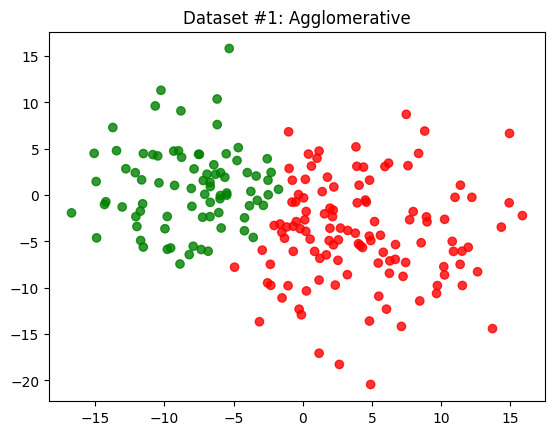

In [ ]:
agglo = AgglomerativeClustering(n_clusters=2) # Instanciamos el modelo
agglo.fit(X1) # Ajuste del modelo
myColors={0:'red', 1:'green'}
plt.scatter(X1[:, 0], X1[:, 1], c=pd.Series(agglo.labels_).apply(lambda x: myColors[x]), alpha=0.8)
plt.title('Dataset #1: Agglomerative')
plt.show()

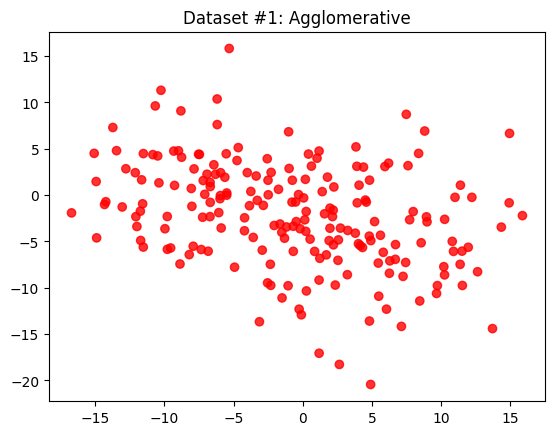

In [ ]:
agglo = AgglomerativeClustering(n_clusters=1) # Instanciamos el modelo
agglo.fit(X1) # Ajuste del modelo
myColors={0:'red', 1:'green'}
plt.scatter(X1[:, 0], X1[:, 1], c=pd.Series(agglo.labels_).apply(lambda x: myColors[x]), alpha=0.8)
plt.title('Dataset #1: Agglomerative')
plt.show()

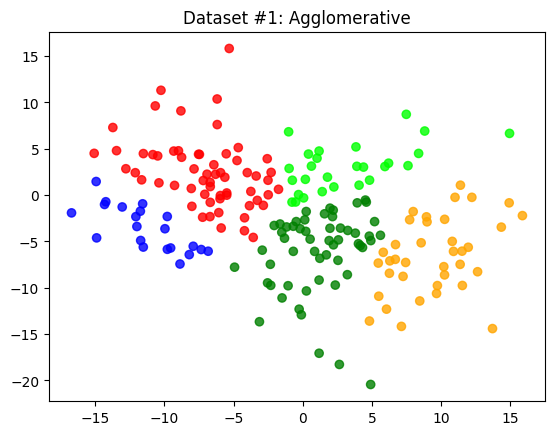

In [ ]:
agglo = AgglomerativeClustering(n_clusters=5) # Instanciamos el modelo
agglo.fit(X1) # Ajuste del modelo
myColors={0:'red', 1:'green', 2:'lime', 3:'orange', 4:'blue'}
plt.scatter(X1[:, 0], X1[:, 1], c=pd.Series(agglo.labels_).apply(lambda x: myColors[x]), alpha=0.8)
plt.title('Dataset #1: Agglomerative')
plt.show()

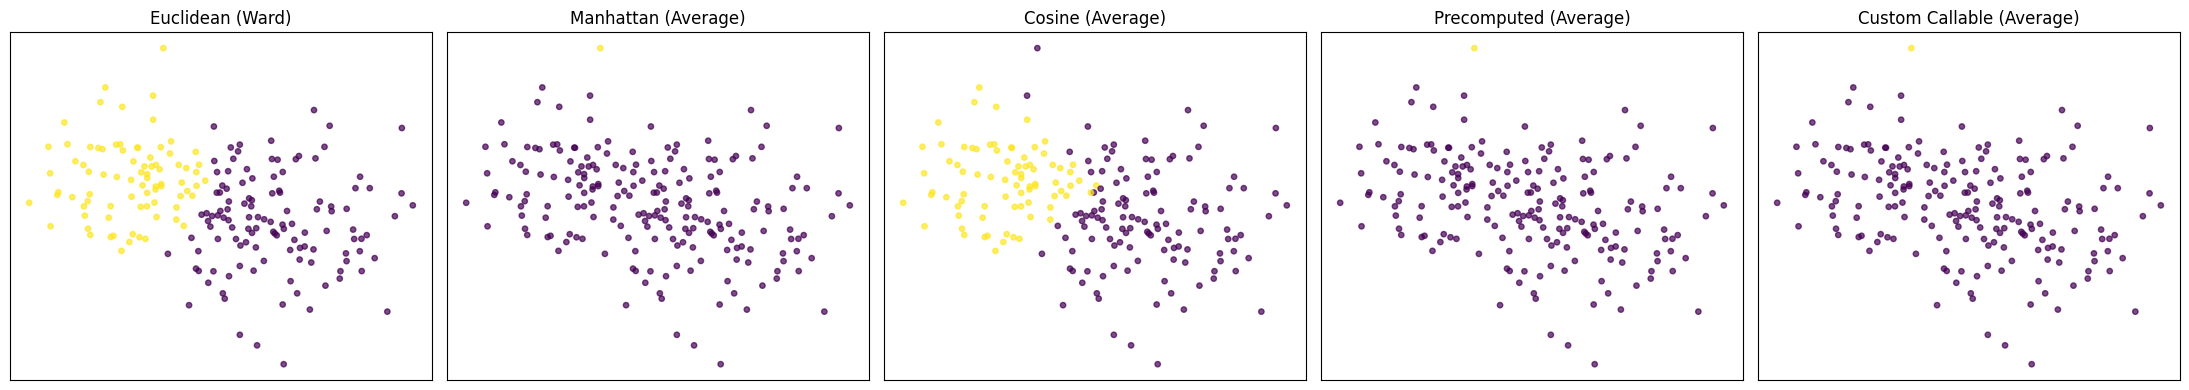

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import pairwise_distances

# Usaremos los datos ya existentes 'X1'
# Nota: Excepto para 'euclidean' con linkage='ward', usaremos linkage='average'
# para que sea compatible con todas las métricas.

# 1. Ejemplo con 'euclidean' (o 'l2') y linkage='ward' (Comportamiento estándar)
model_euclidean = AgglomerativeClustering(n_clusters=2, metric='euclidean', linkage='ward')
labels_euclidean = model_euclidean.fit_predict(X1)

# 2. Ejemplo con 'manhattan' (o 'l1') y linkage='average'
model_manhattan = AgglomerativeClustering(n_clusters=2, metric='manhattan', linkage='average')
labels_manhattan = model_manhattan.fit_predict(X1)

# 3. Ejemplo con 'cosine' y linkage='average'
model_cosine = AgglomerativeClustering(n_clusters=2, metric='cosine', linkage='average')
labels_cosine = model_cosine.fit_predict(X1)

# 4. Ejemplo con 'precomputed' y linkage='average' (Requiere matriz de distancias cuadrada)
# Calculamos previamente la matriz de distancias usando Manhattan como ejemplo
matriz_distancias = pairwise_distances(X1, metric='manhattan')
model_precomputed = AgglomerativeClustering(n_clusters=2, metric='precomputed', linkage='average')
labels_precomputed = model_precomputed.fit_predict(matriz_distancias) # Se pasa la matriz de distancias, no X1

# 5. Ejemplo con un 'callable' (función personalizada) y linkage='average'
# La función debe aceptar la matriz X y devolver la matriz de distancias (n_samples, n_samples)
def mi_distancia_personalizada(X):
    # Aplicamos un peso mayor a la segunda característica antes de calcular distancia euclidiana
    pesos = np.array([1.0, 2.5])
    return pairwise_distances(X * pesos, metric='euclidean')

model_custom = AgglomerativeClustering(n_clusters=2, metric=mi_distancia_personalizada, linkage='average')
labels_custom = model_custom.fit_predict(X1)

# Graficamos para comparar los resultados de cada métrica
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
metodos = [
    (labels_euclidean, "Euclidean (Ward)"),
    (labels_manhattan, "Manhattan (Average)"),
    (labels_cosine, "Cosine (Average)"),
    (labels_precomputed, "Precomputed (Average)"),
    (labels_custom, "Custom Callable (Average)")
]

for ax, (labels, titulo) in zip(axes, metodos):
    ax.scatter(X1[:, 0], X1[:, 1], c=labels, cmap='viridis', alpha=0.7, s=15)
    ax.set_title(titulo)
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.show()

### 1. Métrica Euclídea (`metric='euclidean'`) con Linkage Ward
Esta configuración busca crear clusters compactos de tamaño similar minimizando la varianza intra-cluster.

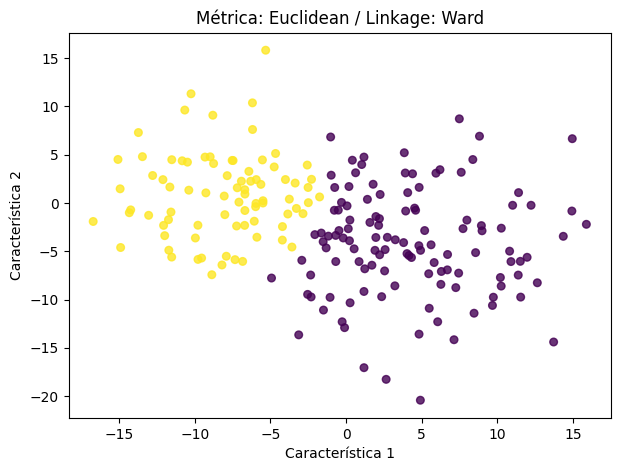

In [ ]:
model_euclidean = AgglomerativeClustering(n_clusters=2, metric='euclidean', linkage='ward')
labels_euclidean = model_euclidean.fit_predict(X1)

plt.figure(figsize=(7, 5))
plt.scatter(X1[:, 0], X1[:, 1], c=labels_euclidean, cmap='viridis', alpha=0.8, s=30)
plt.title("Métrica: Euclidean / Linkage: Ward")
plt.xlabel("Característica 1")
plt.ylabel("Característica 2")
plt.show()

### 2. Métrica Manhattan (`metric='manhattan'`) con Linkage Average
Calcula las distancias basándose en una trayectoria en cuadrícula (suma de diferencias absolutas). Útil si hay valores extremos en dimensiones individuales.

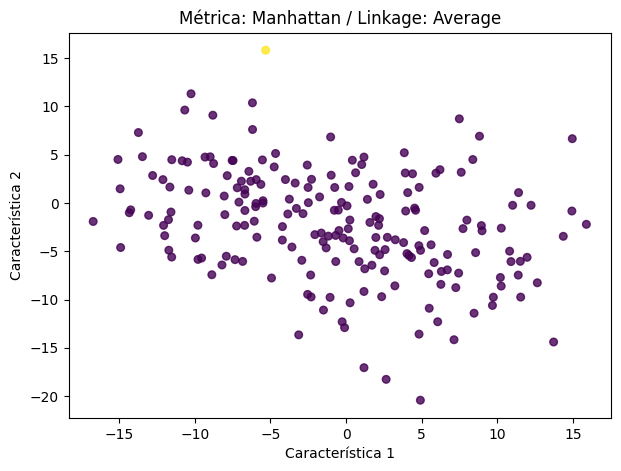

In [ ]:
model_manhattan = AgglomerativeClustering(n_clusters=2, metric='manhattan', linkage='average')
labels_manhattan = model_manhattan.fit_predict(X1)

plt.figure(figsize=(7, 5))
plt.scatter(X1[:, 0], X1[:, 1], c=labels_manhattan, cmap='viridis', alpha=0.8, s=30)
plt.title("Métrica: Manhattan / Linkage: Average")
plt.xlabel("Característica 1")
plt.ylabel("Característica 2")
plt.show()

### 3. Métrica de Coseno (`metric='cosine'`) con Linkage Average
Mide el ángulo entre los vectores respecto al origen. Ideal cuando la magnitud de los datos no es tan importante como su dirección.

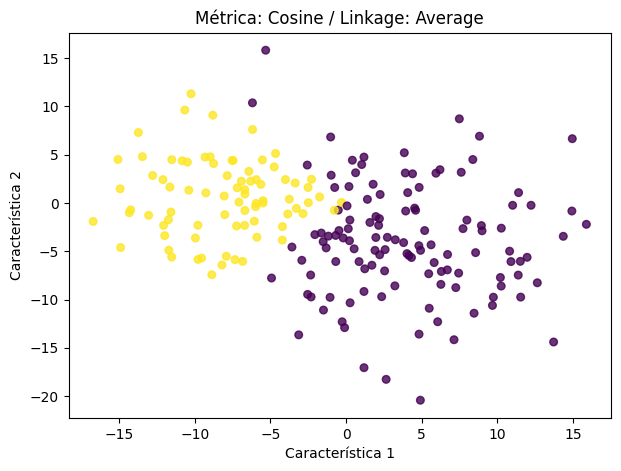

In [ ]:
model_cosine = AgglomerativeClustering(n_clusters=2, metric='cosine', linkage='average')
labels_cosine = model_cosine.fit_predict(X1)

plt.figure(figsize=(7, 5))
plt.scatter(X1[:, 0], X1[:, 1], c=labels_cosine, cmap='viridis', alpha=0.8, s=30)
plt.title("Métrica: Cosine / Linkage: Average")
plt.xlabel("Característica 1")
plt.ylabel("Característica 2")
plt.show()

### 4. Métrica Precomputada (`metric='precomputed'`)
Se le entrega al modelo una matriz de distancias precalculada de tamaño `(n_samples, n_samples)`. En este ejemplo calculamos previamente las distancias usando la métrica Manhattan.

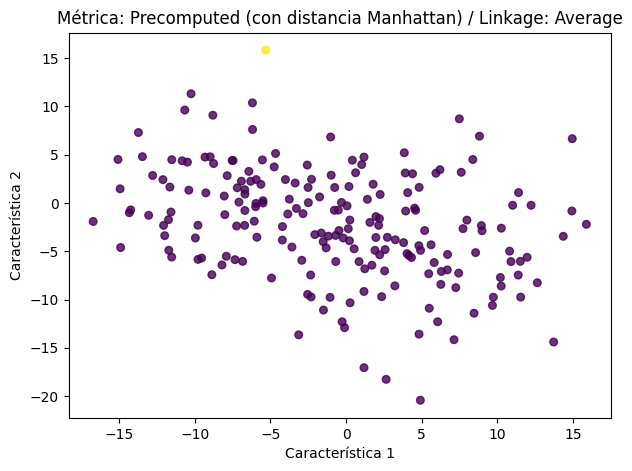

In [ ]:
# 1. Precomputamos la matriz de distancias
matriz_distancias = pairwise_distances(X1, metric='manhattan')

# 2. Entrenamos el modelo indicando 'precomputed'
model_precomputed = AgglomerativeClustering(n_clusters=2, metric='precomputed', linkage='average')
labels_precomputed = model_precomputed.fit_predict(matriz_distancias)

plt.figure(figsize=(7, 5))
plt.scatter(X1[:, 0], X1[:, 1], c=labels_precomputed, cmap='viridis', alpha=0.8, s=30)
plt.title("Métrica: Precomputed (con distancia Manhattan) / Linkage: Average")
plt.xlabel("Característica 1")
plt.ylabel("Característica 2")
plt.show()

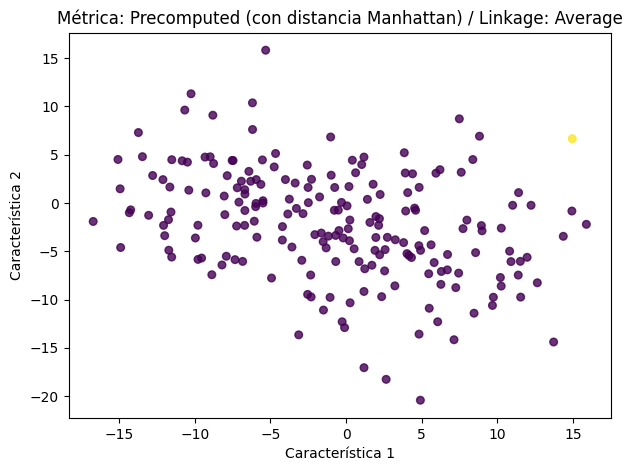

In [ ]:
# 1. Precomputamos la matriz de distancias
matriz_distancias = pairwise_distances(X1, metric='euclidean')

# 2. Entrenamos el modelo indicando 'precomputed'
model_precomputed = AgglomerativeClustering(n_clusters=2, metric='precomputed', linkage='average')
labels_precomputed = model_precomputed.fit_predict(matriz_distancias)

plt.figure(figsize=(7, 5))
plt.scatter(X1[:, 0], X1[:, 1], c=labels_precomputed, cmap='viridis', alpha=0.8, s=30)
plt.title("Métrica: Precomputed (con distancia Manhattan) / Linkage: Average")
plt.xlabel("Característica 1")
plt.ylabel("Característica 2")
plt.show()

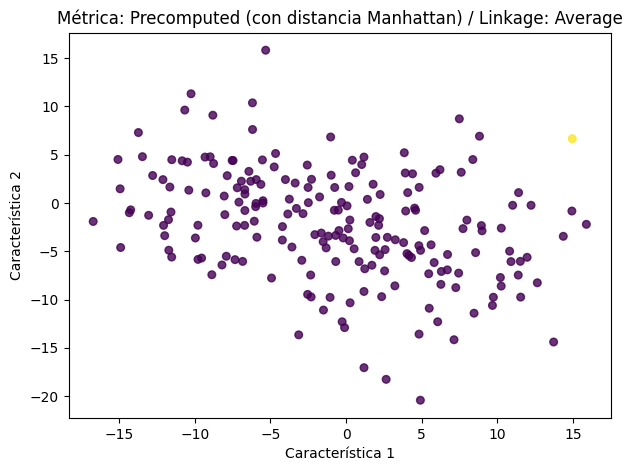

In [ ]:
# 1. Precomputamos la matriz de distancias
matriz_distancias = pairwise_distances(X1, metric='euclidean')

# 2. Entrenamos el modelo indicando 'precomputed'
model_precomputed = AgglomerativeClustering(n_clusters=2, metric='precomputed', linkage='average', compute_distances=True)
labels_precomputed = model_precomputed.fit_predict(matriz_distancias)

plt.figure(figsize=(7, 5))
plt.scatter(X1[:, 0], X1[:, 1], c=labels_precomputed, cmap='viridis', alpha=0.8, s=30)
plt.title("Métrica: Precomputed (con distancia Manhattan) / Linkage: Average")
plt.xlabel("Característica 1")
plt.ylabel("Característica 2")
plt.show()

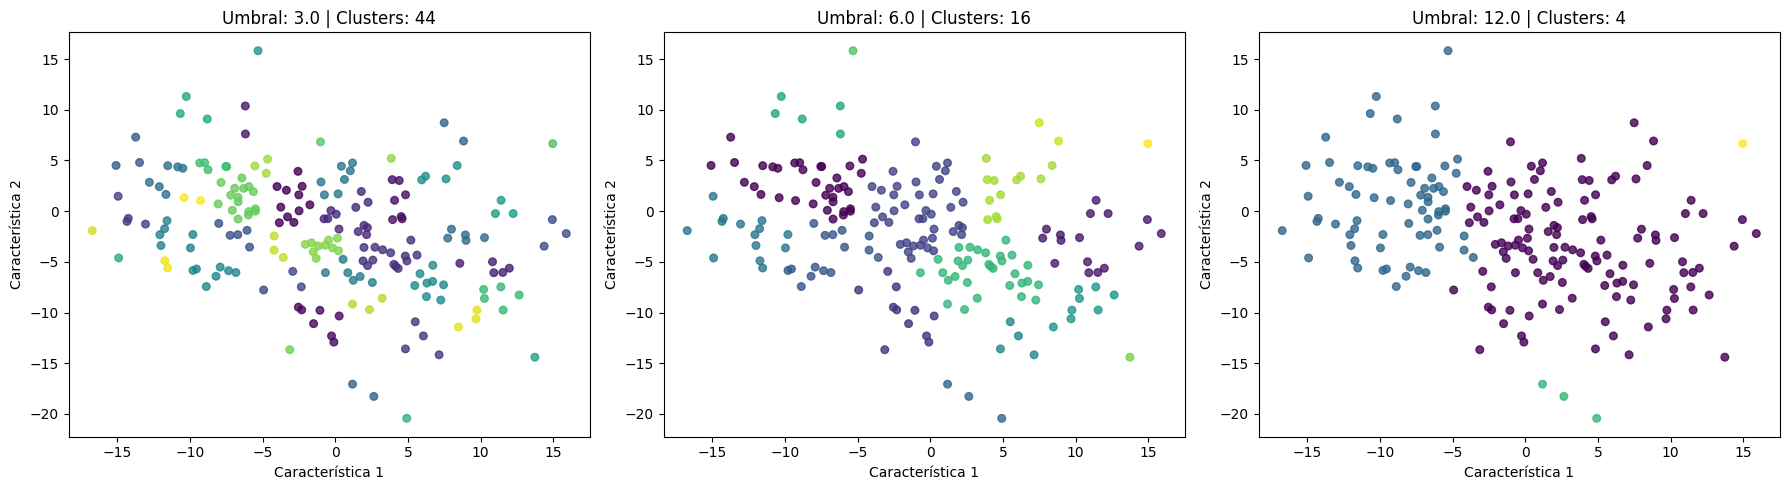

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import pairwise_distances

# 1. Precomputamos la matriz de distancias (usando euclídea sobre X1)
matriz_distancias = pairwise_distances(X1, metric='euclidean')

# 2. Definimos diferentes umbrales (distance_threshold) para experimentar
umbrales = [3.0, 6.0, 12.0]

# Creamos una figura para comparar los resultados lado a lado
fig, axes = plt.subplots(1, len(umbrales), figsize=(18, 5))

for ax, t in zip(axes, umbrales):
    # IMPORTANTE: n_clusters debe ser obligatoriamente None para usar distance_threshold
    modelo = AgglomerativeClustering(
        n_clusters=None,
        distance_threshold=t,
        metric='precomputed',
        linkage='average'
    )

    # Ajustamos y predecimos usando la matriz de distancias
    labels = modelo.fit_predict(matriz_distancias)

    # Graficamos el resultado
    sc = ax.scatter(X1[:, 0], X1[:, 1], c=labels, cmap='viridis', alpha=0.8, s=30)
    ax.set_title(f"Umbral: {t} | Clusters: {modelo.n_clusters_}")
    ax.set_xlabel("Característica 1")
    ax.set_ylabel("Característica 2")

plt.tight_layout()
plt.show()

### 5. Función de Distancia Personalizada (Callable)
Pasamos nuestra propia función de distancia. En este caso ponderamos el eje Y para darle 2.5 veces más peso en la importancia de la distancia, luego calculamos la distancia euclidiana estándar.

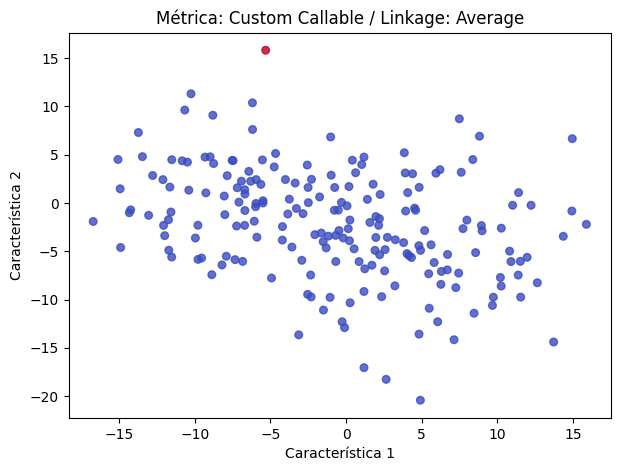

In [ ]:
def mi_distancia_personalizada(X):
    pesos = np.array([1.0, 2.5])
    return pairwise_distances(X * pesos, metric='euclidean')

model_custom = AgglomerativeClustering(n_clusters=2, metric=mi_distancia_personalizada, linkage='average')
labels_custom = model_custom.fit_predict(X1)

plt.figure(figsize=(7, 5))
plt.scatter(X1[:, 0], X1[:, 1], c=labels_custom, cmap='coolwarm', alpha=0.8, s=30)
plt.title("Métrica: Custom Callable / Linkage: Average")
plt.xlabel("Característica 1")
plt.ylabel("Característica 2")
plt.show()

In [ ]:
X_mini = np.array([[1, 2], [1, 4], [1, 0], [4, 2], [4, 4], [4, 0]])
m = AgglomerativeClustering(n_clusters=2, compute_distances=True).fit(X_mini)

n = len(X_mini)
for i, (a, b) in enumerate(m.children_):
    print(f"Paso {i}: nodo {a} + nodo {b} -> nodo {n + i}  "
          f"(distancia {m.distances_[i]:.2f})")
print("labels_:", m.labels_)

Paso 0: nodo 0 + nodo 1 -> nodo 6  (distancia 2.00)
Paso 1: nodo 3 + nodo 5 -> nodo 7  (distancia 2.00)
Paso 2: nodo 2 + nodo 6 -> nodo 8  (distancia 3.46)
Paso 3: nodo 4 + nodo 7 -> nodo 9  (distancia 3.46)
Paso 4: nodo 8 + nodo 9 -> nodo 10  (distancia 5.20)
labels_: [1 1 1 0 0 0]


=== ATRIBUTOS POST-FIT DISPONIBLES ===
1. Número de clusters finales (n_clusters_): 3
2. Número de hojas en el árbol (n_leaves_): 200
3. Componentes conexas calculadas (n_connected_components_): 1
4. Características de entrada analizadas (n_features_in_): 2
5. Primeras 5 etiquetas (labels_): [0 0 0 0 0]

=== RECORRIDO DEL ÁRBOL JERÁRQUICO (children_ y distances_) ===
Paso 0: Se unen (51 + 124) -> Creando el nodo 200 a distancia: 0.0629
Paso 1: Se unen (143 + 176) -> Creando el nodo 201 a distancia: 0.2286
Paso 2: Se unen (119 + 140) -> Creando el nodo 202 a distancia: 0.2326
Paso 3: Se unen (65 + 133) -> Creando el nodo 203 a distancia: 0.2371
Paso 4: Se unen (20 + 107) -> Creando el nodo 204 a distancia: 0.2618
... [Truncado] ...

=== CLUSTERING INDUCTIVO (PREDICCIONES) ===
Nuevo punto [-12  -2] asignado inductivamente al Cluster: 0
Nuevo punto [ 6 -6] asignado inductivamente al Cluster: 0
Nuevo punto [0 8] asignado inductivamente al Cluster: 0


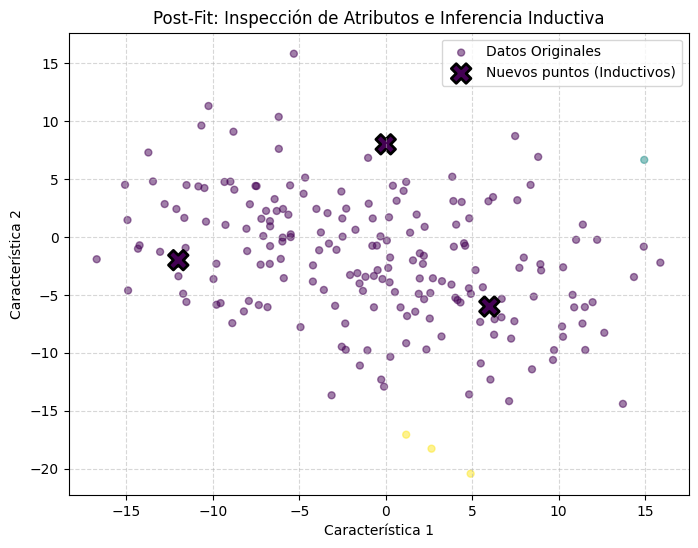

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering
from sklearn.neighbors import KNeighborsClassifier

# --- 1. Ajuste del modelo base y lectura de atributos clave ---
# Usamos compute_distances=True para poder acceder a m.distances_
model = AgglomerativeClustering(
    n_clusters=3,
    metric='euclidean',
    linkage='average',
    compute_distances=True
)
labels = model.fit_predict(X1)

print("=== ATRIBUTOS POST-FIT DISPONIBLES ===")
print(f"1. Número de clusters finales (n_clusters_): {model.n_clusters_}")
print(f"2. Número de hojas en el árbol (n_leaves_): {model.n_leaves_}")
print(f"3. Componentes conexas calculadas (n_connected_components_): {model.n_connected_components_}")
print(f"4. Características de entrada analizadas (n_features_in_): {model.n_features_in_}")
print(f"5. Primeras 5 etiquetas (labels_): {model.labels_[:5]}\n")

# --- 2. Lectura y recorrido del árbol jerárquico ---
print("=== RECORRIDO DEL ÁRBOL JERÁRQUICO (children_ y distances_) ===")
n_samples = len(X1)
# Mostramos las primeras 5 fusiones en el árbol
for i in range(5):
    nodo_a = model.children_[i, 0]
    nodo_b = model.children_[i, 1]
    distancia = model.distances_[i]
    nuevo_nodo = n_samples + i
    print(f"Paso {i}: Se unen ({nodo_a} + {nodo_b}) -> Creando el nodo {nuevo_nodo} a distancia: {distancia:.4f}")
print("... [Truncado] ...\n")

# --- 3. Clustering Inductivo (¿Cómo predecir nuevos datos?) ---
# Como AgglomerativeClustering carece de '.predict()', usamos KNeighborsClassifier como puente
clasificador = KNeighborsClassifier(n_neighbors=5)
clasificador.fit(X1, labels)

# Definimos nuevos puntos de los cuales queremos predecir su clúster
puntos_nuevos = np.array([
    [-12, -2],  # Extremo izquierdo
    [6, -6],    # Cuadrante inferior derecho
    [0, 8]      # Parte superior
])

predicciones = clasificador.predict(puntos_nuevos)
print("=== CLUSTERING INDUCTIVO (PREDICCIONES) ===")
for punto, clus in zip(puntos_nuevos, predicciones):
    print(f"Nuevo punto {punto} asignado inductivamente al Cluster: {clus}")

# --- 4. Graficación del Resultado ---
plt.figure(figsize=(8, 6))
plt.scatter(X1[:, 0], X1[:, 1], c=labels, cmap='viridis', alpha=0.5, s=25, label='Datos Originales')
plt.scatter(puntos_nuevos[:, 0], puntos_nuevos[:, 1], c=predicciones, cmap='viridis',
            marker='X', s=200, edgecolors='black', linewidths=2, label='Nuevos puntos (Inductivos)')

plt.title("Post-Fit: Inspección de Atributos e Inferencia Inductiva")
plt.xlabel("Característica 1")
plt.ylabel("Característica 2")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

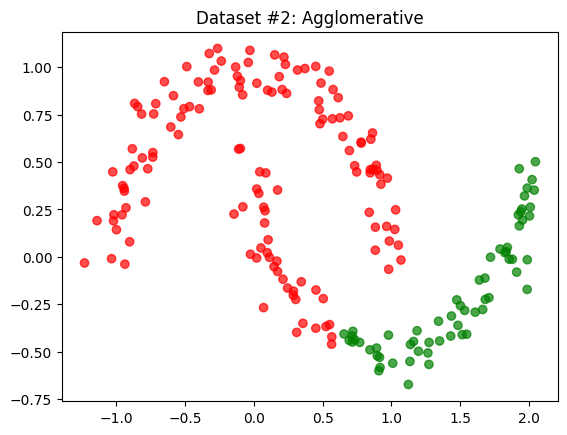

In [ ]:
agglo = AgglomerativeClustering(n_clusters=2)
agglo.fit(X2)
myColors={0:'red', 1:'green'}   # Define a color palette: 0~1.
plt.scatter(X2[:, 0], X2[:, 1], c=pd.Series(agglo.labels_).apply(lambda x: myColors[x]), alpha=0.7)
plt.title('Dataset #2: Agglomerative')
plt.show()

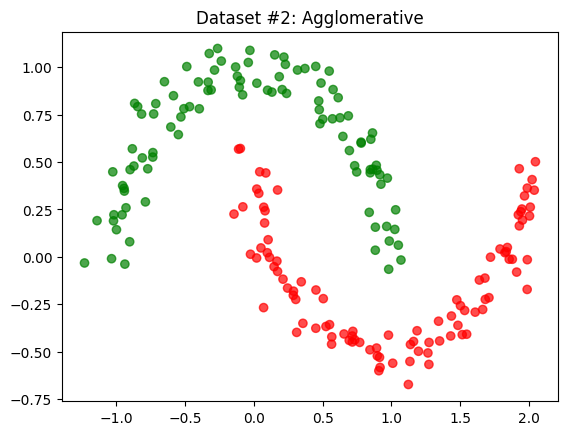

In [ ]:
agglo = AgglomerativeClustering(n_clusters=2, linkage='single')
agglo.fit(X2)
myColors={0:'red', 1:'green'}   # Define a color palette: 0~1.
plt.scatter(X2[:, 0], X2[:, 1], c=pd.Series(agglo.labels_).apply(lambda x: myColors[x]), alpha=0.7)
plt.title('Dataset #2: Agglomerative')
plt.show()

In [ ]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

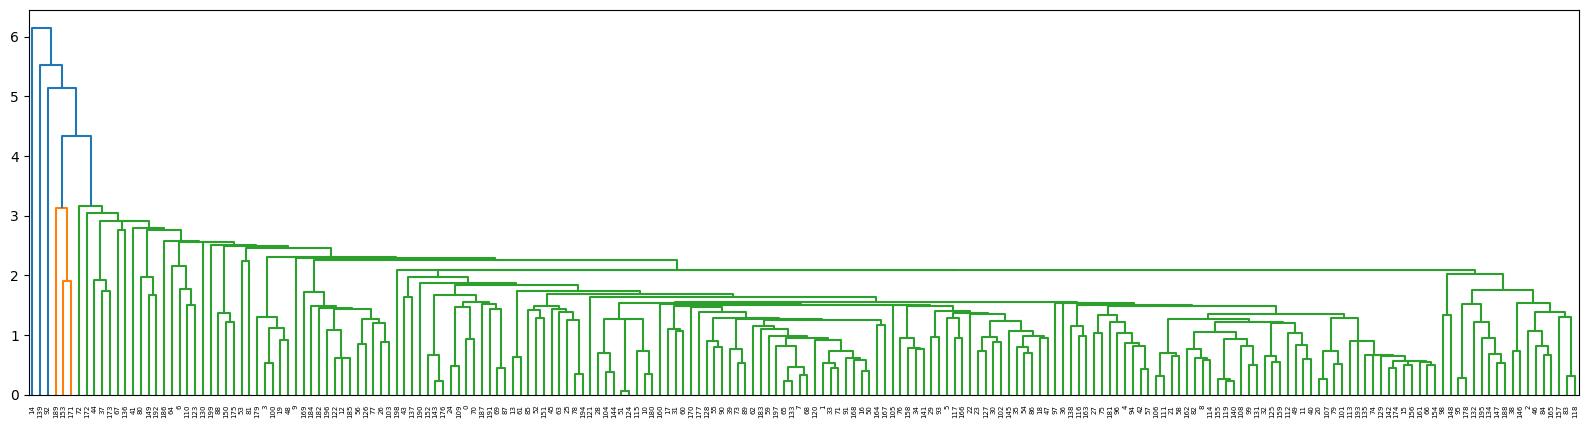

In [ ]:
myLinkage = linkage(X1, method='single')
plt.figure(figsize=(20, 5))
dendrogram(myLinkage)
plt.show()

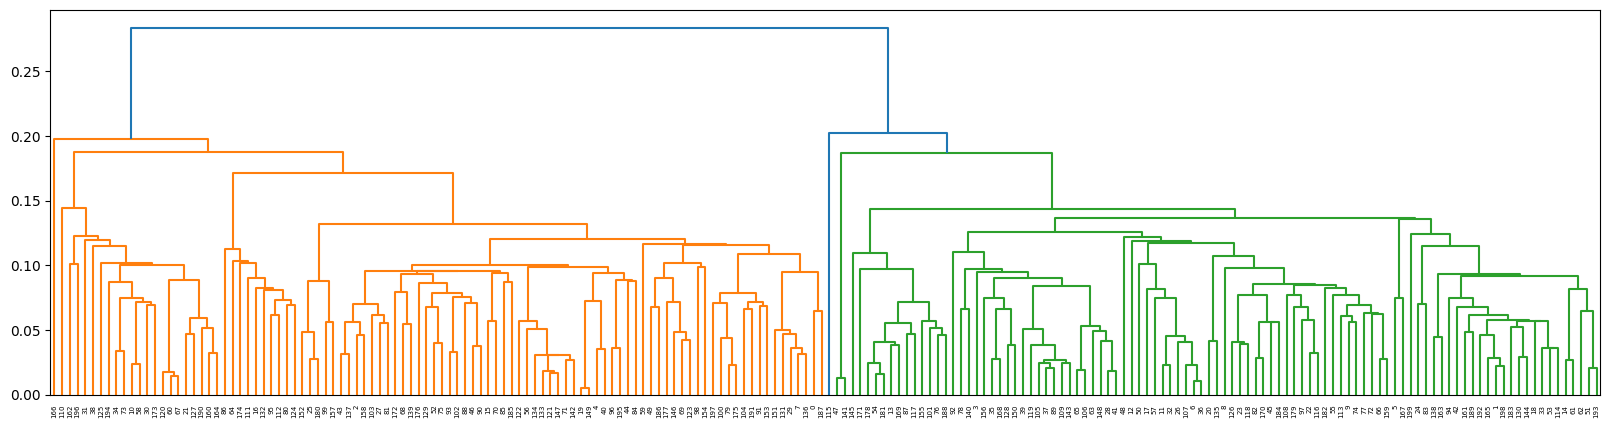

In [ ]:
myLinkage = linkage(X2, method='single')
plt.figure(figsize=(20, 5))
dendrogram(myLinkage)
plt.show()

In [ ]:
labels = fcluster(myLinkage, 5, criterion='distance')
pd.Series(labels).value_counts()

,count
1,200


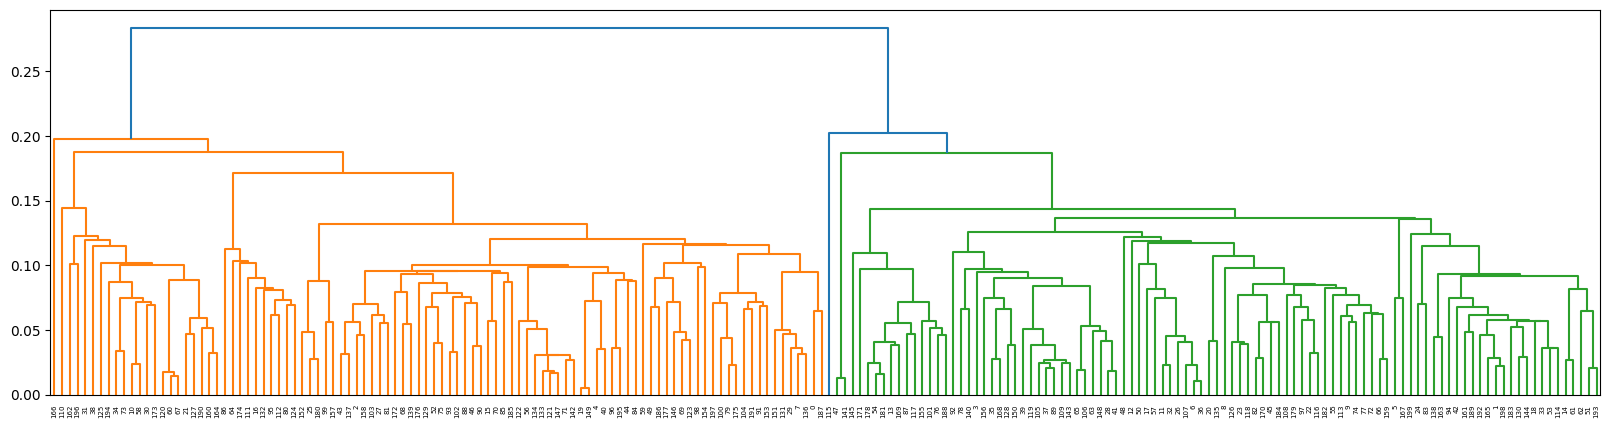

In [ ]:
myLinkage = linkage(X2, method='single')
plt.figure(figsize=(20, 5))
dendrogram(myLinkage)
plt.show()

In [ ]:
labels = fcluster(myLinkage, 0.23, criterion='distance')
pd.Series(labels).value_counts()

,count
1,100
2,100


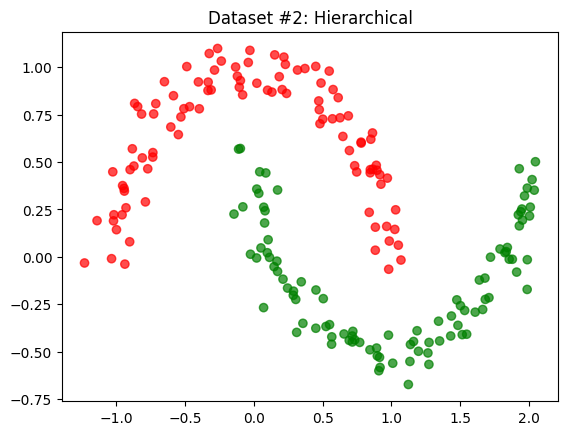

In [ ]:
myColors={1: 'red', 2: 'green'}
plt.scatter(X2[:, 0], X2[:, 1], c=pd.Series(labels).apply(lambda x: myColors[x]), alpha=0.7)
plt.title('Dataset #2: Hierarchical')
plt.show()

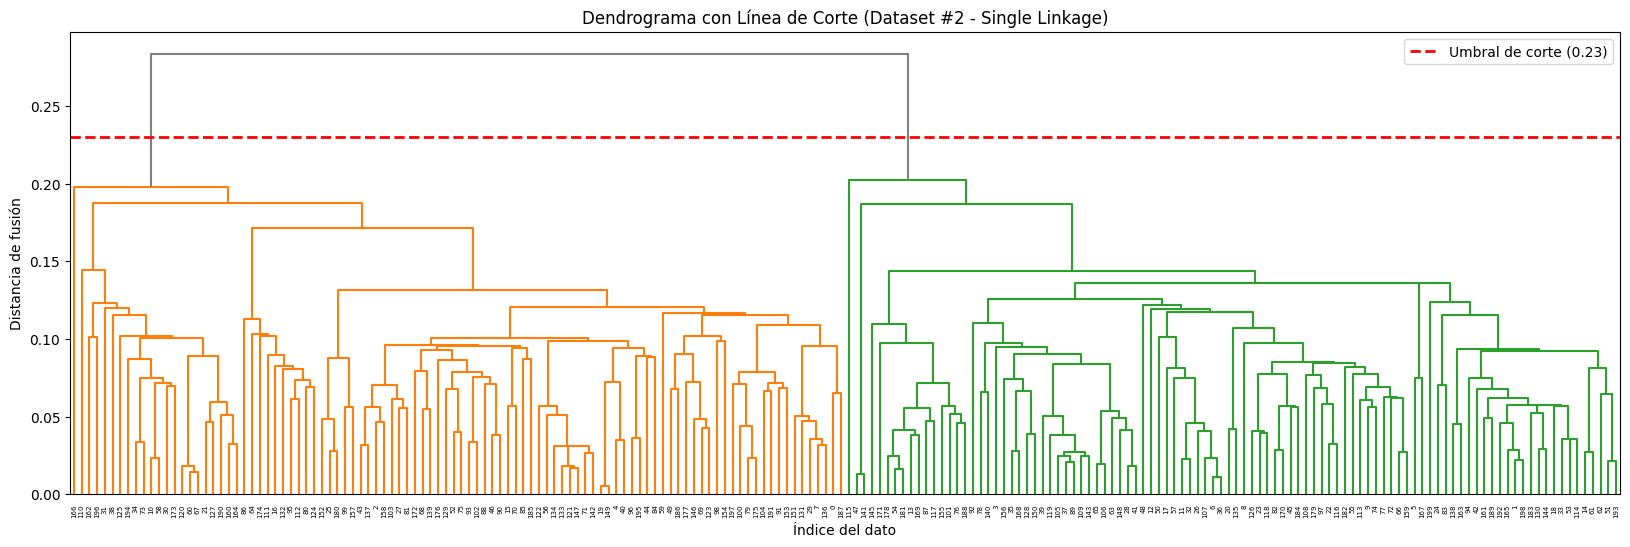

In [ ]:
# 1. Definimos el punto de corte (umbral de distancia)
umbral_corte = 0.23

plt.figure(figsize=(20, 6))

# 2. El parámetro 'color_threshold' colorea las ramas que se separan bajo el umbral
dendrogram(
    myLinkage,
    color_threshold=umbral_corte,
    above_threshold_color='gray' # Mantiene en gris las uniones superiores al corte
)

# 3. Dibujamos la línea horizontal que representa físicamente el corte en el eje Y
plt.axhline(y=umbral_corte, color='red', linestyle='--', linewidth=2, label=f'Umbral de corte ({umbral_corte})')

plt.title('Dendrograma con Línea de Corte (Dataset #2 - Single Linkage)')
plt.xlabel('Índice del dato')
plt.ylabel('Distancia de fusión')
plt.legend()
plt.show()

In [ ]:
from sklearn.datasets import load_iris

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
%matplotlib inline

In [ ]:
iris=load_iris()

In [ ]:
iris

{'data': array([[5.1, 3.5, 1.4, 0.2],
        [4.9, 3. , 1.4, 0.2],
        [4.7, 3.2, 1.3, 0.2],
        [4.6, 3.1, 1.5, 0.2],
        [5. , 3.6, 1.4, 0.2],
        [5.4, 3.9, 1.7, 0.4],
        [4.6, 3.4, 1.4, 0.3],
        [5. , 3.4, 1.5, 0.2],
        [4.4, 2.9, 1.4, 0.2],
        [4.9, 3.1, 1.5, 0.1],
        [5.4, 3.7, 1.5, 0.2],
        [4.8, 3.4, 1.6, 0.2],
        [4.8, 3. , 1.4, 0.1],
        [4.3, 3. , 1.1, 0.1],
        [5.8, 4. , 1.2, 0.2],
        [5.7, 4.4, 1.5, 0.4],
        [5.4, 3.9, 1.3, 0.4],
        [5.1, 3.5, 1.4, 0.3],
        [5.7, 3.8, 1.7, 0.3],
        [5.1, 3.8, 1.5, 0.3],
        [5.4, 3.4, 1.7, 0.2],
        [5.1, 3.7, 1.5, 0.4],
        [4.6, 3.6, 1. , 0.2],
        [5.1, 3.3, 1.7, 0.5],
        [4.8, 3.4, 1.9, 0.2],
        [5. , 3. , 1.6, 0.2],
        [5. , 3.4, 1.6, 0.4],
        [5.2, 3.5, 1.5, 0.2],
        [5.2, 3.4, 1.4, 0.2],
        [4.7, 3.2, 1.6, 0.2],
        [4.8, 3.1, 1.6, 0.2],
        [5.4, 3.4, 1.5, 0.4],
        [5.2, 4.1, 1.5, 0.1],
  

In [ ]:
iris_data=iris.data
iris_data_pd=pd.DataFrame(iris.data, columns=iris.feature_names)
iris_data_pd

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


In [ ]:
iris_data_pd.iloc[:, 2:4]

,petal length (cm),petal width (cm)
0,1.4,0.2
1,1.4,0.2
2,1.3,0.2
3,1.5,0.2
4,1.4,0.2
...,...,...
145,5.2,2.3
146,5.0,1.9
147,5.2,2.0
148,5.4,2.3


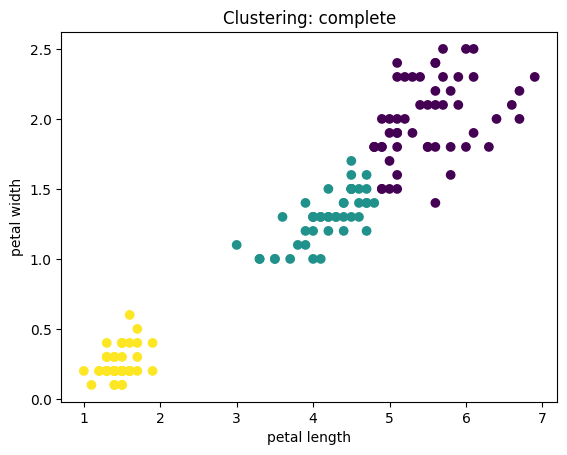

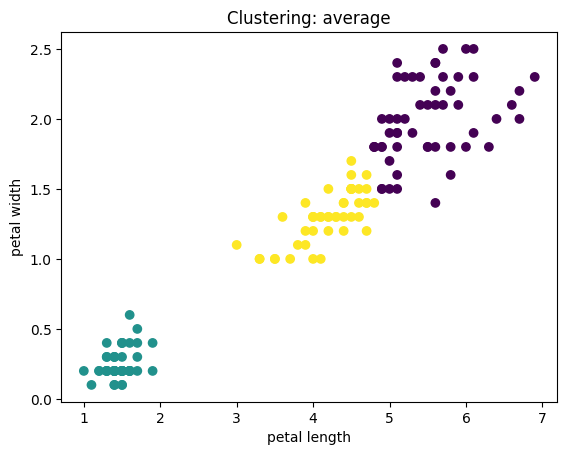

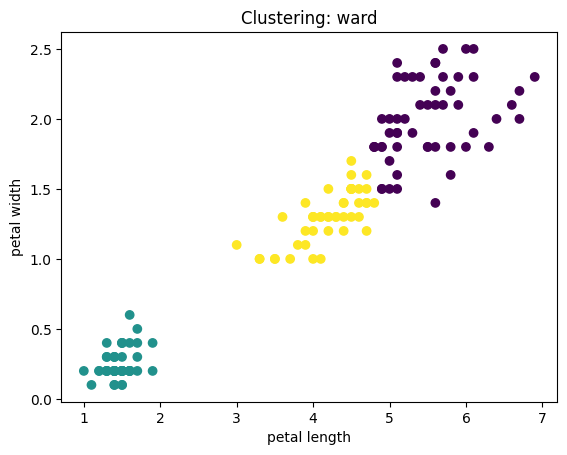

In [ ]:
from sklearn.cluster import AgglomerativeClustering
linkage=["complete", "average", "ward"]
for idx, i in enumerate(linkage):
    plt.figure(idx)
    hier=AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage=i)
    hier.fit(iris_data_pd.iloc[:, 2:4])
    plt.scatter(iris_data_pd.iloc[:, 2], iris_data_pd.iloc[:, 3], c=hier.labels_)
    plt.title("Clustering: "+ i)
    plt.xlabel('petal length')
    plt.ylabel('petal width')
    plt.show()

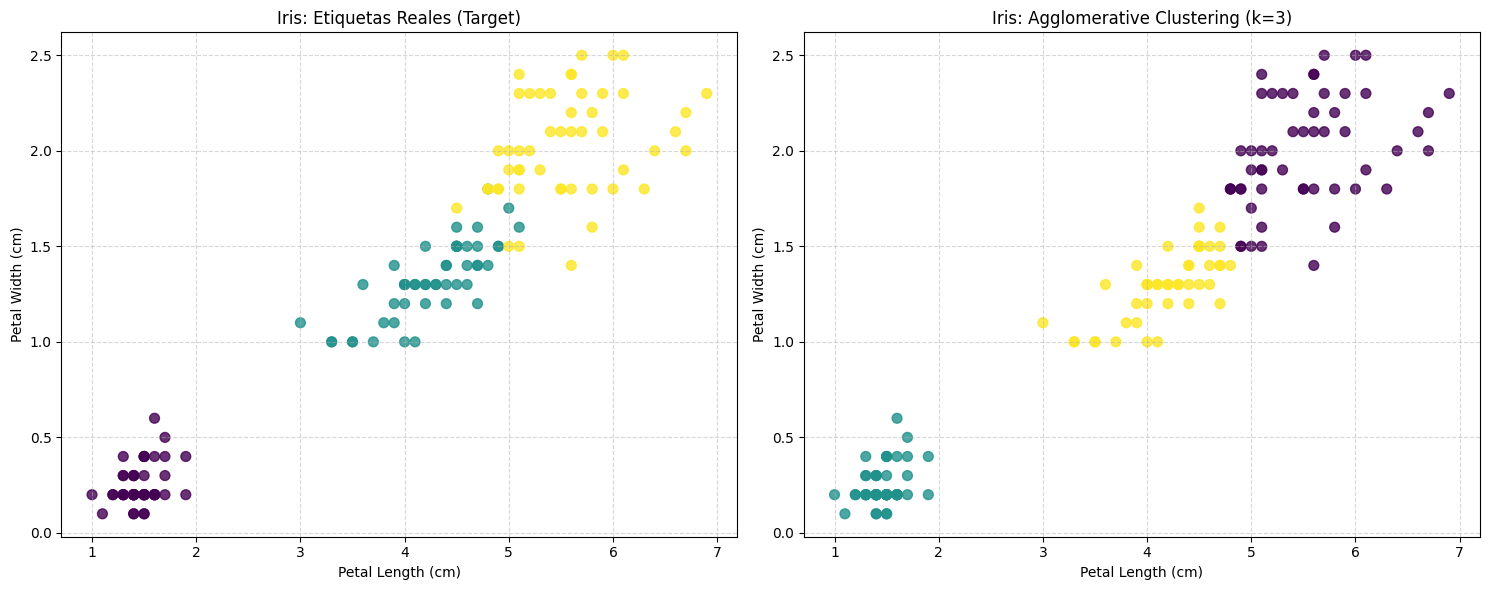

In [ ]:
import matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering

# 1. Ajustamos el modelo aglomerativo con 3 clusters (ward por defecto)
hier_iris = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
pred_labels = hier_iris.fit_predict(iris_data_pd.iloc[:, 2:4])

# 2. Creamos la figura con subplots lado a lado
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Subplot izquierdo: Datos reales (target)
scatter_real = axes[0].scatter(
    iris_data_pd.iloc[:, 2],
    iris_data_pd.iloc[:, 3],
    c=iris.target,
    cmap='viridis',
    alpha=0.8,
    s=50
)
axes[0].set_title("Iris: Etiquetas Reales (Target)")
axes[0].set_xlabel("Petal Length (cm)")
axes[0].set_ylabel("Petal Width (cm)")
axes[0].grid(True, linestyle='--', alpha=0.5)

# Subplot derecho: Agrupamiento aglomerativo
scatter_pred = axes[1].scatter(
    iris_data_pd.iloc[:, 2],
    iris_data_pd.iloc[:, 3],
    c=pred_labels,
    cmap='viridis',
    alpha=0.8,
    s=50
)
axes[1].set_title("Iris: Agglomerative Clustering (k=3)")
axes[1].set_xlabel("Petal Length (cm)")
axes[1].set_ylabel("Petal Width (cm)")
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
from scipy.cluster import hierarchy

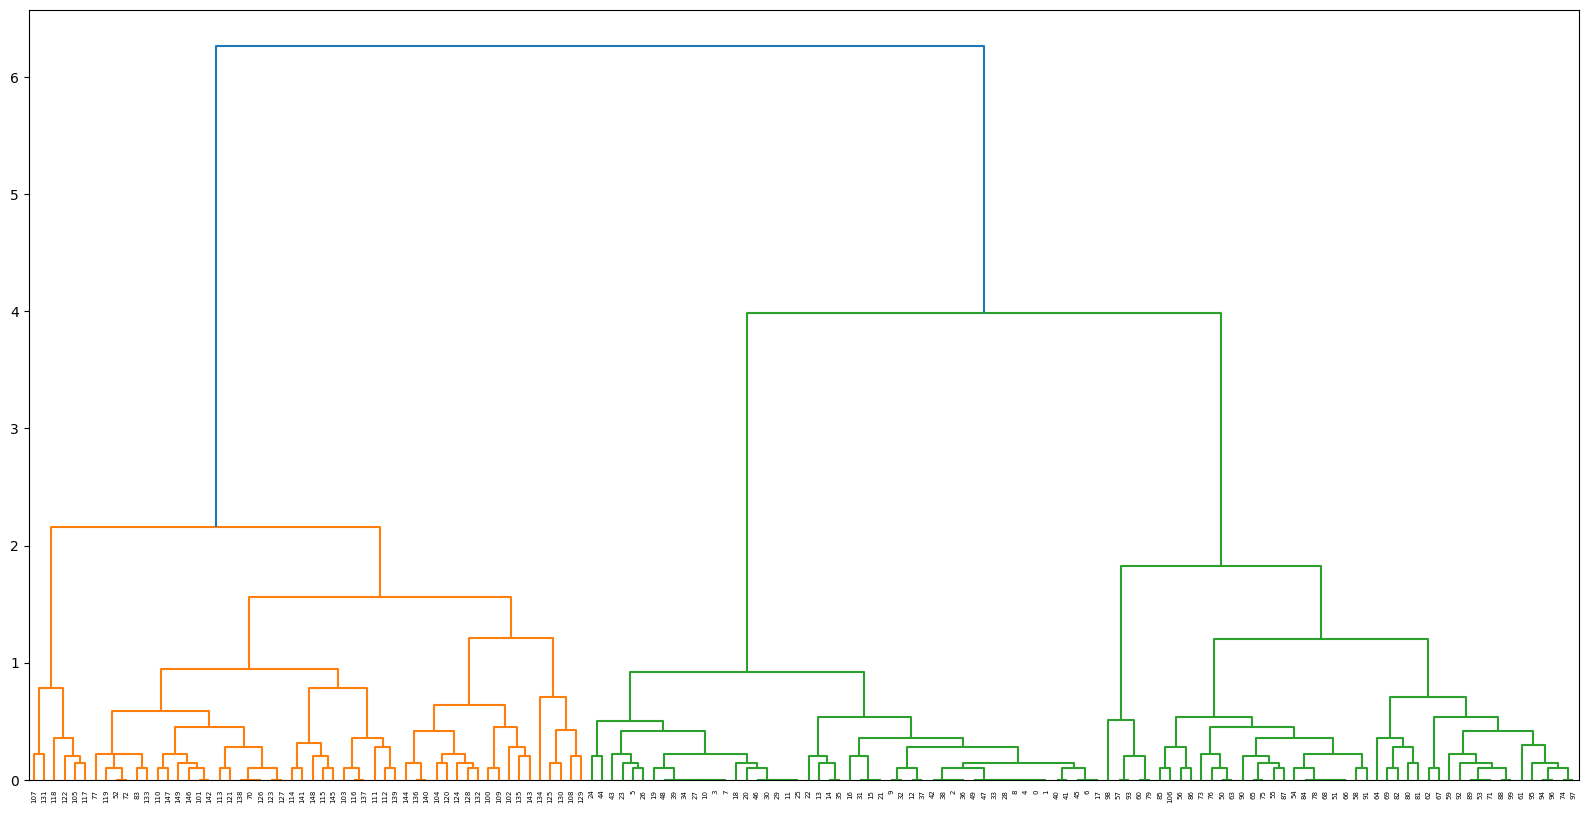

In [ ]:
hierar = hierarchy.linkage(iris_data_pd.iloc[:, 2:4], 'complete')
plt.figure(figsize=(20, 10))
dh = hierarchy.dendrogram(hierar)
plt.show()

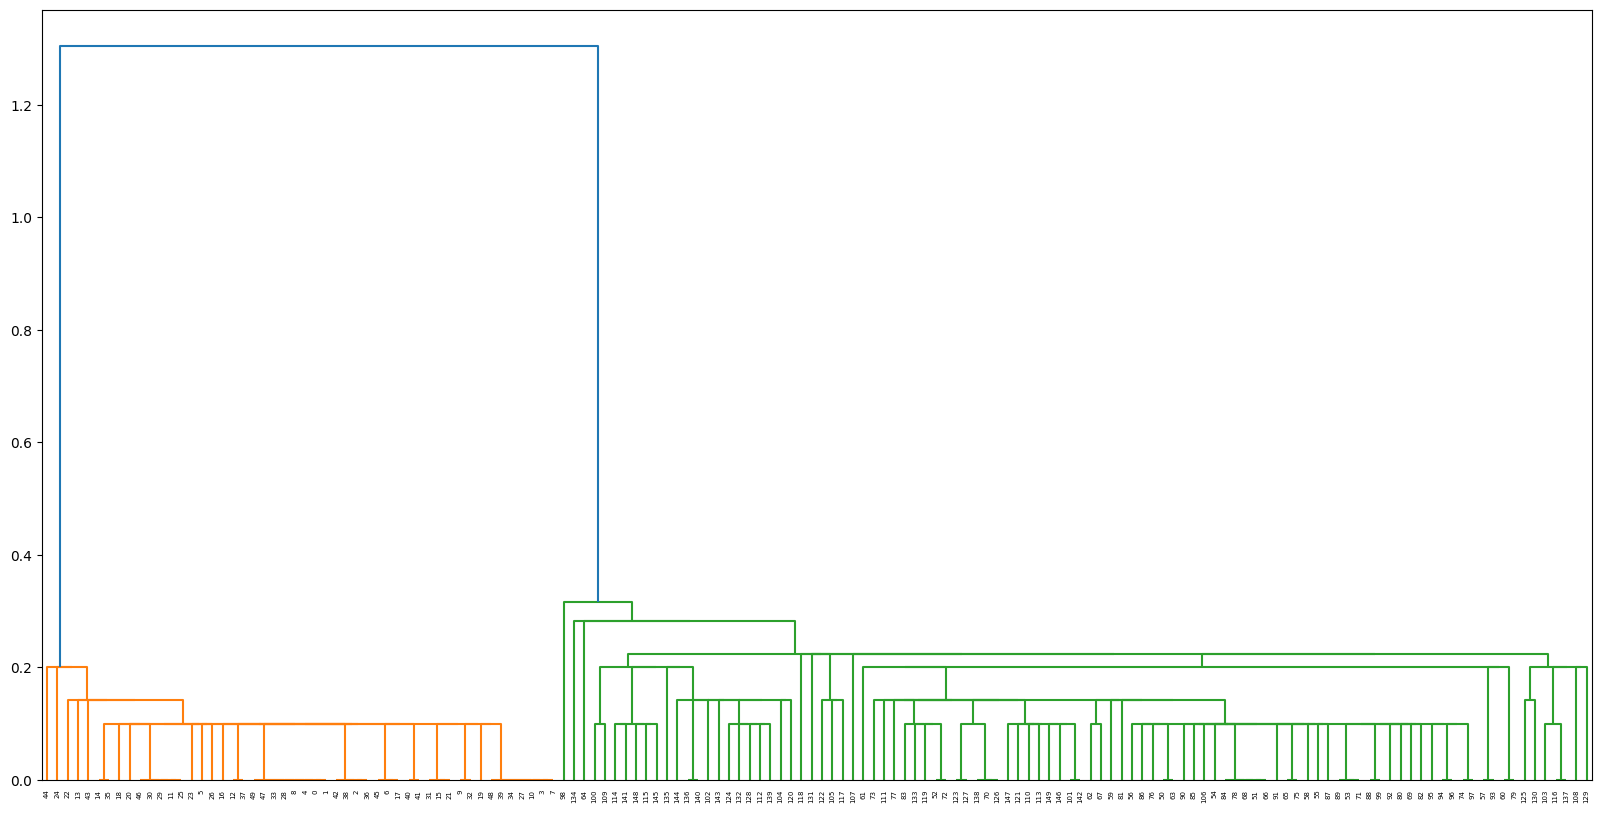

In [ ]:
hierar = hierarchy.linkage(iris_data_pd.iloc[:, 2:4], 'single')
plt.figure(figsize=(20, 10))
dh = hierarchy.dendrogram(hierar)
plt.show()

# SIC 2026 · Inteligencia Artificial
## Clase 8: Aprendizaje no supervisado (continuación) y taller de segmentación

**Samsung Innovation Campus Chile 2026 · ONG Innovacien**

En la Clase 7 vimos precision, recall y F1, y K-medias hasta los ejercicios de escalado. Hoy terminamos el Capítulo 6 y lo aplicamos en un taller completo.

| Hora | Actividad |
|---|---|
| 18:00 a 18:20 | Parte 0. Repaso de K-medias y ejercicios pendientes de la Clase 7 |
| 18:20 a 18:55 | Parte 1. Clustering jerárquico |
| 18:55 a 19:30 | Parte 2. DBSCAN |
| 19:30 a 19:40 | Pausa |
| 19:40 a 20:20 | Parte 3. PCA |
| 20:20 a 21:45 | Parte 4. Taller: segmentación completa de clientes |
| 21:45 a 22:00 | Cierre |

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

def revisar(condicion, mensaje_ok="Correcto.", mensaje_error="Todavía no. Revisa tu respuesta."):
    """Imprime si un ejercicio está bien resuelto."""
    try:
        print(mensaje_ok if condicion() else mensaje_error)
    except Exception:
        print(mensaje_error)

def cargar_telco():
    try:
        import kagglehub
        carpeta = kagglehub.dataset_download("blastchar/telco-customer-churn")
        return pd.read_csv(os.path.join(carpeta, "WA_Fn-UseC_-Telco-Customer-Churn.csv"))
    except Exception:
        return pd.read_csv("https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv")

print("Listo.")

---
# Parte 0. Repaso de K-medias

En la Clase 7 segmentamos a los clientes de la compañía de telecomunicaciones usando solo la antigüedad y el cargo mensual:

1. **Escalamos** los datos, porque K-medias usa distancias.
2. Probamos k de 2 a 8 con el **método del codo** y el **coeficiente de silueta**: ambos indicaron k = 4.
3. **Interpretamos** los segmentos y, recién al final, miramos su tasa de fuga: el segmento de clientes nuevos con cargo alto tenía cerca de 50% de fuga, y el de antiguos con cargo bajo, cerca de 5%.

Reconstruimos ese resultado para seguir desde ahí.

In [ ]:
clientes = cargar_telco()
datos_seg = clientes[["tenure", "MonthlyCharges"]]

escalador = StandardScaler().fit(datos_seg)
X_seg = escalador.transform(datos_seg)

km4 = KMeans(n_clusters=4, n_init=10, random_state=42).fit(X_seg)
clientes["segmento"] = km4.labels_

# Centroides en la escala original: inverse_transform deshace el escalado
centroides = escalador.inverse_transform(km4.cluster_centers_)

plt.figure(figsize=(7, 4.5))
sns.scatterplot(data=clientes, x="tenure", y="MonthlyCharges", hue="segmento", palette="tab10", s=8, alpha=0.6)
plt.scatter(centroides[:, 0], centroides[:, 1], s=250, c="red", marker="*", edgecolors="black", label="Centroides")
plt.xlabel("Antigüedad (meses)"); plt.ylabel("Cargo mensual (USD)"); plt.title("Cuatro segmentos y sus centroides")
plt.legend(); plt.show()

clientes.groupby("segmento").agg(
    clientes=("tenure", "size"), antiguedad_media=("tenure", "mean"), cargo_medio=("MonthlyCharges", "mean"),
    tasa_fuga=("Churn", lambda s: (s == "Yes").mean()),
).round(2).sort_values("tasa_fuga", ascending=False)

## Ejercicios pendientes de la Clase 7

### Ejercicio 1
Entrena un K-medias con **k = 3** sobre `X_seg` (con `n_init=10` y `random_state=42`) y guarda su coeficiente de silueta en `silueta_k3`. Usa `sample_size=3000, random_state=0` en `silhouette_score`. ¿Es mejor o peor que el de k = 4 (0,483)?

In [ ]:
silueta_k3 = None  # TU CÓDIGO AQUÍ
print(silueta_k3)

In [ ]:
_ref = silhouette_score(X_seg, KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(X_seg), sample_size=3000, random_state=0)
revisar(lambda: np.isclose(silueta_k3, _ref))

### Ejercicio 2
¿Qué pasa si **no escalamos**? Imaginemos que el cargo mensual estuviera en **pesos chilenos**. La celda crea `datos_clp` con ese cambio. Entrena un K-medias con k = 4 directamente sobre `datos_clp` (sin escalar), guarda las etiquetas en `etiquetas_sin_escalar` y grafica el resultado. ¿Qué variable domina la división y por qué?

In [ ]:
datos_clp = datos_seg.assign(MonthlyCharges=datos_seg["MonthlyCharges"] * 950)   # tipo de cambio de ejemplo

etiquetas_sin_escalar = None  # TU CÓDIGO AQUÍ

In [ ]:
revisar(lambda: np.array_equal(etiquetas_sin_escalar, KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(datos_clp)))

---
# Parte 1. Clustering jerárquico

> **Definición. Clustering jerárquico aglomerativo:** parte con cada observación como un grupo propio y, en cada paso, **une los dos grupos más parecidos**, hasta que todo queda en un solo grupo. El resultado es un árbol llamado **dendrograma**.

Ventaja frente a K-medias: no hay que elegir k de antemano. Se mira el dendrograma y se "corta" a la altura que tenga sentido.

> **Criterio de enlace (linkage):** define la distancia entre dos grupos.
>
> - **Ward:** une los grupos que menos aumentan la variación interna. Tiende a formar grupos compactos y de tamaño parecido.
> - **Complete:** usa la distancia entre los dos puntos **más lejanos** de los grupos.
> - **Average:** usa el **promedio** de las distancias entre todos los pares de puntos.
> - **Single:** usa la distancia entre los dos puntos **más cercanos**. Tiende a formar "cadenas".

Usamos el dataset **wine** de scikit-learn: 178 vinos de tres productores, con 13 medidas químicas. Tomamos 40 vinos para que el dendrograma se pueda leer.

In [ ]:
from sklearn.datasets import load_wine
from scipy.cluster.hierarchy import linkage, dendrogram

vinos = load_wine(as_frame=True)
X_vino = StandardScaler().fit_transform(vinos.data)
y_vino = vinos.target          # el productor real: NO se usa para agrupar, solo para comparar al final

rng = np.random.default_rng(0)
idx = rng.choice(len(X_vino), size=40, replace=False)
enlaces = linkage(X_vino[idx], method="ward")

plt.figure(figsize=(12, 4.5))
dendrogram(enlaces, labels=[f"P{p}" for p in y_vino.values[idx]], leaf_font_size=8, color_threshold=12)
plt.axhline(12, ls="--", color="gray")
plt.title("Dendrograma de 40 vinos (la etiqueta indica el productor real)")
plt.ylabel("Distancia de unión"); plt.show()

**Cómo leerlo:** abajo cada vino es un grupo. Hacia arriba se van uniendo. La altura de cada unión indica cuán distintos eran los grupos que se unieron. Si cortamos con la línea gris, quedan **3 grupos**, y cada grupo concentra mayoritariamente a un productor, aunque el algoritmo nunca vio esa información. Hay algunos vinos mezclados: el agrupamiento no es perfecto, y eso es normal.

**¿Dónde cortar?** Donde haya un "salto" grande de altura entre uniones consecutivas: significa que se estarían uniendo grupos muy distintos.

Con scikit-learn, para todo el dataset:

In [ ]:
from sklearn.cluster import AgglomerativeClustering

jerarquico = AgglomerativeClustering(n_clusters=3, linkage="ward").fit(X_vino)
pd.crosstab(jerarquico.labels_, y_vino, rownames=["Grupo encontrado"], colnames=["Productor real"])

Los números de los grupos son arbitrarios: el "grupo 0" no tiene por qué ser el "productor 0". Lo que importa es que cada grupo concentre a un productor.

### ¿Importa el criterio de enlace?

Para comparar, usamos el **índice de Rand ajustado (ARI)**, que mide cuánto coincide una agrupación con otra: 1 es coincidencia perfecta y 0 es lo mismo que el azar. Solo se puede usar cuando, excepcionalmente, conocemos la respuesta real, como aquí.

In [ ]:
from sklearn.metrics import adjusted_rand_score

for criterio in ["ward", "complete", "average", "single"]:
    etiquetas = AgglomerativeClustering(n_clusters=3, linkage=criterio).fit_predict(X_vino)
    tamanos = np.bincount(etiquetas)
    print(f"{criterio:9s} ARI = {adjusted_rand_score(y_vino, etiquetas):.3f} | tamaño de los grupos: {tamanos}")

El criterio de enlace cambia todo. Con **single** y **average**, casi todos los vinos quedan en un solo grupo gigante y los otros dos grupos tienen uno o dos vinos: el efecto "cadena". **Ward** es la opción por defecto razonable.

### Ejercicio 3
Repite el dendrograma de los 40 vinos usando `method="single"` y guarda el resultado de `linkage` en `enlaces_single`. Grafícalo y compáralo con el de Ward: ¿se ven grupos claros?

In [ ]:
enlaces_single = None  # TU CÓDIGO AQUÍ

In [ ]:
revisar(lambda: np.allclose(enlaces_single, linkage(X_vino[idx], method="single")))

---
# Parte 2. DBSCAN: grupos con forma libre

K-medias supone que los grupos son "bolitas" alrededor de un centroide. Cuando los grupos tienen otras formas, falla.

> **Definición. DBSCAN:** forma grupos con las zonas donde hay **muchos puntos juntos** (alta densidad). Dos parámetros:
>
> - `eps`: el radio del vecindario de cada punto.
> - `min_samples`: cuántos vecinos necesita un punto dentro de ese radio para ser "núcleo" de un grupo.
>
> Los puntos que no quedan en ninguna zona densa se marcan como **ruido** (etiqueta -1). No hay que elegir k.

In [ ]:
from sklearn.datasets import make_moons
from sklearn.cluster import DBSCAN

X_luna, y_luna = make_moons(n_samples=300, noise=0.07, random_state=0)
X_luna = StandardScaler().fit_transform(X_luna)

etiquetas_km = KMeans(n_clusters=2, n_init=10, random_state=0).fit_predict(X_luna)
etiquetas_db = DBSCAN(eps=0.3, min_samples=5).fit_predict(X_luna)

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))
ejes[0].scatter(X_luna[:, 0], X_luna[:, 1], c=etiquetas_km, cmap="coolwarm", s=15); ejes[0].set_title("K-medias (k = 2)")
ejes[1].scatter(X_luna[:, 0], X_luna[:, 1], c=etiquetas_db, cmap="coolwarm", s=15); ejes[1].set_title("DBSCAN (eps = 0,3)")
plt.show()
print(f"ARI K-medias: {adjusted_rand_score(y_luna, etiquetas_km):.3f} | ARI DBSCAN: {adjusted_rand_score(y_luna, etiquetas_db):.3f}")
print("Grupos DBSCAN:", sorted(set(etiquetas_db)), "| Puntos de ruido:", (etiquetas_db == -1).sum())

K-medias corta las lunas por la mitad con una línea recta. DBSCAN sigue la forma de cada luna.

### ¿Cómo elegir eps? El gráfico de k-distancia

Elegir `eps` a ojo es difícil. Un método práctico:

1. Para cada punto, calcular la distancia a su vecino número `min_samples`.
2. Ordenar esas distancias de menor a mayor y graficarlas.
3. Buscar el **codo**: donde la curva empieza a subir rápido. Los puntos a la derecha del codo están lejos de todo (son ruido), y el valor del codo es un buen `eps`.

In [ ]:
from sklearn.neighbors import NearestNeighbors

vecinos = NearestNeighbors(n_neighbors=5).fit(X_luna)
distancias, _ = vecinos.kneighbors(X_luna)
k_distancia = np.sort(distancias[:, -1])     # distancia al 5.º vecino (el primero es el propio punto)

plt.figure(figsize=(7, 4))
plt.plot(k_distancia)
plt.axhline(0.3, ls="--", color="gray", label="eps = 0,3")
plt.xlabel("Puntos ordenados por distancia"); plt.ylabel("Distancia al 5.º vecino")
plt.title("Gráfico de k-distancia: el codo sugiere eps"); plt.legend(); plt.show()

### DBSCAN para detectar anomalías

Como DBSCAN marca como ruido a los puntos aislados, sirve para **detectar casos raros**: transacciones sospechosas, sensores con lecturas anómalas o errores de digitación. Agregamos 10 puntos "extraños" a las lunas y vemos si los detecta.

In [ ]:
rng = np.random.default_rng(1)
anomalias = rng.uniform(-2.5, 2.5, size=(10, 2))
X_con_anomalias = np.vstack([X_luna, anomalias])

etiquetas = DBSCAN(eps=0.3, min_samples=5).fit_predict(X_con_anomalias)
es_anomalia = np.r_[np.zeros(len(X_luna)), np.ones(10)].astype(bool)

plt.figure(figsize=(7, 4.5))
plt.scatter(X_con_anomalias[:, 0], X_con_anomalias[:, 1], c=(etiquetas == -1), cmap="coolwarm", s=18)
plt.scatter(anomalias[:, 0], anomalias[:, 1], facecolors="none", edgecolors="black", s=120, label="Anomalías agregadas")
plt.title("En rojo, los puntos que DBSCAN marcó como ruido"); plt.legend(); plt.show()
print("Anomalías agregadas detectadas como ruido:", int((etiquetas[es_anomalia] == -1).sum()), "de 10")

Algunas anomalías quedan cerca de las lunas y DBSCAN las considera parte de un grupo. Es una limitación esperable: un punto raro que cae dentro de una zona densa no se distingue de los demás.

### Ejercicio 4
Prueba DBSCAN sobre `X_luna` con `eps=0.1`, `eps=0.2` y `eps=0.5` (con `min_samples=5`). Para cada uno, guarda en el diccionario `n_grupos` cuántos grupos encuentra **sin contar el ruido**. ¿Qué pasa con un eps muy chico y con uno muy grande? Compáralo con el gráfico de k-distancia.

In [ ]:
n_grupos = {}
for eps in [0.1, 0.2, 0.5]:
    pass  # TU CÓDIGO AQUÍ
n_grupos

In [ ]:
_esp = {e: len(set(DBSCAN(eps=e, min_samples=5).fit_predict(X_luna)) - {-1}) for e in [0.1, 0.2, 0.5]}
revisar(lambda: n_grupos == _esp)

---
# Parte 3. PCA: resumir muchas columnas en pocas

> **Definición. Análisis de componentes principales (PCA):** crea nuevas variables, llamadas **componentes**, que son combinaciones de las originales. La primera componente es la dirección en que los datos **varían más**; la segunda, la que varía más entre las perpendiculares a la primera, y así sucesivamente.

Para qué sirve:

1. **Visualizar** datos de muchas dimensiones en 2D.
2. **Reducir** el número de columnas antes de un modelo, cuando hay muchas y están correlacionadas.
3. **Quitar ruido**, quedándose con las componentes que explican más variación.

> **Varianza explicada:** proporción de la variación total de los datos que captura cada componente.

Los vinos tienen 13 medidas químicas: imposible de graficar. Con PCA las resumimos en 2.

In [ ]:
from sklearn.decomposition import PCA

pca = PCA().fit(X_vino)
var = pca.explained_variance_ratio_

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
ejes[0].bar(range(1, 14), var, color="#1428A0", label="Por componente")
ejes[0].plot(range(1, 14), var.cumsum(), marker="o", color="orange", label="Acumulada")
ejes[0].set_xlabel("Componente"); ejes[0].set_ylabel("Varianza explicada"); ejes[0].set_title("¿Cuánta información guarda cada componente?")
ejes[0].legend()

pca2 = PCA(n_components=2).fit(X_vino)
Z = pca2.transform(X_vino)
sc = ejes[1].scatter(Z[:, 0], Z[:, 1], c=y_vino, cmap="viridis", s=20)
ejes[1].set_xlabel("Componente 1"); ejes[1].set_ylabel("Componente 2"); ejes[1].set_title("13 medidas resumidas en 2 (color: productor real)")
plt.colorbar(sc, ax=ejes[1]); plt.tight_layout(); plt.show()

print(f"Las 2 primeras componentes explican el {var[:2].sum():.1%} de la variación total")

Con solo 2 de 13 dimensiones, que guardan algo más de la mitad de la variación, los tres productores se ven claramente separados.

### ¿Qué significa cada componente? Las cargas

Cada componente es una combinación de las variables originales. Los **coeficientes** de esa combinación se llaman **cargas** (loadings): indican cuánto pesa cada variable. Mirar las cargas más grandes (en valor absoluto) permite ponerle nombre a una componente.

In [ ]:
cargas = pd.DataFrame(pca2.components_.T, index=vinos.data.columns, columns=["Componente 1", "Componente 2"])

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
for eje, col in zip(ejes, cargas.columns):
    cargas[col].sort_values().plot(kind="barh", ax=eje, color="#1428A0", title=f"Cargas de la {col.lower()}")
plt.tight_layout(); plt.show()

La componente 1 combina sobre todo fenoles, flavonoides y la medida de dilución (od280), con signo positivo, y el ácido málico y otras con signo negativo: resume la "intensidad fenólica" del vino. La componente 2 está dominada por el color, el alcohol y la prolina: resume el "cuerpo" del vino. No siempre se puede nombrar una componente con tanta claridad, pero vale la pena intentarlo. Ojo: el signo de una componente es arbitrario y puede aparecer invertido; lo que importa es qué variables van juntas y cuáles en sentido contrario.

### PCA + K-medias

In [ ]:
km_13 = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(X_vino)
km_2 = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(Z)
print(f"K-medias con las 13 medidas: ARI = {adjusted_rand_score(y_vino, km_13):.3f}")
print(f"K-medias con 2 componentes:   ARI = {adjusted_rand_score(y_vino, km_2):.3f}")

Con 2 componentes se obtiene prácticamente el mismo resultado que con las 13 columnas: PCA comprimió los datos sin perder lo importante para separar los grupos.

### PCA antes de un modelo supervisado

El dataset **digits** tiene imágenes de dígitos escritos a mano de 8 × 8 pixeles: 64 columnas. ¿Cuánto perdemos si las resumimos con PCA antes de clasificar? Ponemos PCA **dentro del Pipeline**, para que se ajuste solo con los datos de entrenamiento de cada pliegue.

In [ ]:
from sklearn.datasets import load_digits
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

digitos = load_digits()
fig, ejes = plt.subplots(1, 8, figsize=(10, 1.6))
for eje, img, etiqueta in zip(ejes, digitos.images, digitos.target):
    eje.imshow(img, cmap="gray_r"); eje.set_title(etiqueta); eje.axis("off")
plt.show()

resultados = []
for n in [5, 10, 20, 30, 64]:
    pipe = Pipeline([("escalar", StandardScaler()), ("pca", PCA(n_components=n)), ("modelo", LogisticRegression(max_iter=3000))])
    resultados.append({"Componentes": n, "Exactitud CV": cross_val_score(pipe, digitos.data, digitos.target, cv=5).mean()})
pd.DataFrame(resultados).round(3)

Con 30 componentes, menos de la mitad de las 64 columnas, la exactitud baja muy poco. En datasets grandes, esto hace los modelos más rápidos y livianos. Con muy pocas componentes, en cambio, se pierde información útil y la exactitud cae.

### Ejercicio 5
¿Cuántas componentes se necesitan para explicar **al menos el 80%** de la variación de los vinos? Usa `var.cumsum()` y guarda la respuesta en `n_componentes_80`.

In [ ]:
n_componentes_80 = None  # TU CÓDIGO AQUÍ
print(n_componentes_80)

In [ ]:
revisar(lambda: n_componentes_80 == int(np.argmax(var.cumsum() >= 0.8) + 1))

---
# Parte 4. Taller: segmentación completa de clientes

En la Clase 7 segmentamos con solo 2 variables. Una compañía real usaría toda la información: qué servicios tiene cada cliente, su contrato, su forma de pago. Ahora hacemos la segmentación completa, aplicando todo el capítulo.

**Objetivo del taller:** encontrar segmentos de clientes que el equipo comercial pueda entender y usar, y responder si esos segmentos ayudan a predecir la fuga.

## Paso 1. Preparar los datos

Usamos variables numéricas (antigüedad y cargos) y los servicios contratados. Igual que en la Clase 6, `TotalCharges` viene como texto con 11 vacíos de clientes nuevos: los convertimos a número y los rellenamos con 0, porque esos clientes aún no han pagado nada.

**No incluimos `Churn`:** es lo que queremos explicar al final, y el clustering no debe verlo.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

clientes["TotalCharges"] = pd.to_numeric(clientes["TotalCharges"], errors="coerce").fillna(0)

NUM = ["tenure", "MonthlyCharges", "TotalCharges"]
CAT = ["Contract", "InternetService", "PaymentMethod", "OnlineSecurity", "TechSupport", "StreamingTV",
       "StreamingMovies", "PaperlessBilling", "PhoneService", "MultipleLines", "OnlineBackup", "DeviceProtection"]

prep_seg = ColumnTransformer([
    ("num", StandardScaler(), NUM),
    ("cat", OneHotEncoder(sparse_output=False), CAT),
])
X_full = prep_seg.fit_transform(clientes)
print("Clientes:", X_full.shape[0], "| Columnas después de transformar:", X_full.shape[1])

## Paso 2. Visualizar con PCA

38 columnas no se pueden graficar. Con PCA las bajamos a 2 solo para **mirar** los datos: el clustering lo haremos con todas las columnas.

In [ ]:
pca_full = PCA(n_components=2).fit(X_full)
Z_full = pca_full.transform(X_full)
print(f"Varianza explicada por 2 componentes: {pca_full.explained_variance_ratio_.sum():.1%}")

plt.figure(figsize=(7, 4.5))
plt.scatter(Z_full[:, 0], Z_full[:, 1], s=4, alpha=0.3)
plt.xlabel("Componente 1"); plt.ylabel("Componente 2"); plt.title("Clientes en 2D con PCA")
plt.show()

Se ven agrupaciones: ya hay estructura que un clustering puede encontrar.

## Paso 3. Elegir k

### Ejercicio 6
Para k de 2 a 7, entrena un K-medias sobre `X_full` (con `n_init=10` y `random_state=42`) y calcula el coeficiente de silueta (con `sample_size=3000, random_state=0`). Guarda los resultados en el diccionario `siluetas_full`, con k como clave. ¿Qué k recomienda la silueta?

In [ ]:
siluetas_full = {}
for k in range(2, 8):
    pass  # TU CÓDIGO AQUÍ
siluetas_full

In [ ]:
_k = 5
_r = silhouette_score(X_full, KMeans(n_clusters=_k, n_init=10, random_state=42).fit_predict(X_full), sample_size=3000, random_state=0)
revisar(lambda: len(siluetas_full) == 6 and np.isclose(siluetas_full[_k], _r))

**Dos observaciones importantes:**

1. Los valores de silueta son **más bajos** que en la Clase 7 (alrededor de 0,3 contra 0,48). Es normal: con muchas columnas, sobre todo categóricas, los grupos están menos separados. No significa que la segmentación sea mala.
2. La silueta favorece k = 3, pero **la silueta no es la única guía**. Comparamos k = 3 y k = 4 por lo que más importa: si los segmentos sirven para el negocio.

## Paso 4. Interpretar los segmentos

In [ ]:
def perfil_segmentos(k):
    etiquetas = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X_full)
    tabla = clientes.assign(seg=etiquetas).groupby("seg").agg(
        clientes=("tenure", "size"),
        antiguedad=("tenure", "mean"),
        cargo_mensual=("MonthlyCharges", "mean"),
        sin_internet=("InternetService", lambda s: (s == "No").mean()),
        fibra=("InternetService", lambda s: (s == "Fiber optic").mean()),
        mes_a_mes=("Contract", lambda s: (s == "Month-to-month").mean()),
        streaming_tv=("StreamingTV", lambda s: (s == "Yes").mean()),
        tasa_fuga=("Churn", lambda s: (s == "Yes").mean()),
    ).round(2)
    return etiquetas, tabla.sort_values("tasa_fuga", ascending=False)

etiquetas_k3, perfil_k3 = perfil_segmentos(3)
etiquetas_k4, perfil_k4 = perfil_segmentos(4)
print("k = 3"); display(perfil_k3)
print("k = 4"); display(perfil_k4)

**Con k = 3** salen tres segmentos claros: clientes sin internet (fuga muy baja), clientes nuevos con internet y contrato mes a mes (fuga alta) y clientes antiguos con muchos servicios (fuga baja).

**Con k = 4**, el segmento de fuga alta se divide en dos: clientes con **fibra óptica**, contrato mes a mes y cargo alto, con una fuga cercana al 57%, y clientes con **DSL** y cargo medio, con una fuga cercana al 25%.

Esa división es muy útil para el negocio: dice que el problema de fuga se concentra en los clientes nuevos de fibra. Por eso, aunque la silueta prefiere k = 3, **k = 4 es mejor elección para este objetivo**. Elegir k es una decisión técnica **y** de negocio.

### Ejercicio 7
Ponle un **nombre de negocio** a cada uno de los 4 segmentos de `perfil_k4` (por ejemplo, "Fieles sin internet"). Guarda un diccionario `nombres_segmentos` con el número de segmento como clave y el nombre como valor. Este ejercicio no tiene verificación automática: discútanlo en grupo.

In [ ]:
nombres_segmentos = {}  # TU CÓDIGO AQUÍ, por ejemplo {0: "...", 1: "...", 2: "...", 3: "..."}

## Paso 5. Ver los segmentos en el mapa de PCA

In [ ]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
for eje, etiquetas, titulo in [(ejes[0], etiquetas_k4, "Segmentos (k = 4)"),
                               (ejes[1], (clientes["Churn"] == "Yes").astype(int), "Fuga real (1 = se fue)")]:
    sc = eje.scatter(Z_full[:, 0], Z_full[:, 1], c=etiquetas, cmap="tab10" if "Segmentos" in titulo else "coolwarm", s=4, alpha=0.5)
    eje.set_title(titulo); eje.set_xlabel("Componente 1"); eje.set_ylabel("Componente 2")
    plt.colorbar(sc, ax=eje)
plt.tight_layout(); plt.show()

A la izquierda los segmentos; a la derecha, la fuga real. Las zonas con más fuga coinciden con uno de los segmentos, aunque el clustering nunca vio esa columna.

## Paso 6. ¿Los segmentos mejoran el modelo de fuga?

Una idea común: usar el segmento como característica extra en el modelo supervisado. Lo probamos sin fuga de datos: el K-medias va **dentro del Pipeline**, así que en cada pliegue de la validación cruzada se ajusta solo con los datos de entrenamiento.

`FeatureUnion` junta dos transformaciones en paralelo: las columnas originales (`passthrough`) y la **distancia de cada cliente a cada centroide** (`KMeans.transform`).

In [ ]:
from sklearn.pipeline import FeatureUnion
from sklearn.model_selection import StratifiedKFold

y_fuga = (clientes["Churn"] == "Yes").astype(int)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

modelo_base = Pipeline([("prep", prep_seg), ("modelo", LogisticRegression(max_iter=3000))])
modelo_con_segmentos = Pipeline([
    ("prep", prep_seg),
    ("union", FeatureUnion([("originales", "passthrough"),
                            ("distancias", KMeans(n_clusters=4, n_init=10, random_state=42))])),
    ("modelo", LogisticRegression(max_iter=3000)),
])

auc_base = cross_val_score(modelo_base, clientes, y_fuga, cv=cv, scoring="roc_auc").mean()
auc_seg = cross_val_score(modelo_con_segmentos, clientes, y_fuga, cv=cv, scoring="roc_auc").mean()
print(f"ROC AUC sin segmentos: {auc_base:.4f}")
print(f"ROC AUC con segmentos: {auc_seg:.4f}")

**La mejora es mínima.** ¿Por qué? Porque los segmentos se construyeron con las mismas variables que el modelo ya tiene: no le entregan información nueva, solo la reorganizan.

Esta es una conclusión valiosa, no un fracaso. El clustering no siempre mejora la predicción, pero sí sirve para **entender** a los clientes y **comunicar** el problema: "la fuga se concentra en los clientes nuevos de fibra con contrato mes a mes" es una frase que un gerente puede usar para decidir.

---
# Cierre

| Método | Qué hace | Hay que elegir | Fortaleza | Debilidad |
|---|---|---|---|---|
| K-medias | Grupos alrededor de centroides | k | Rápido y fácil de interpretar | Supone grupos redondos y de tamaño parecido |
| Jerárquico | Une grupos paso a paso | Criterio de enlace y dónde cortar | Muestra la estructura completa | Lento con muchos datos; sensible al enlace |
| DBSCAN | Grupos por densidad | eps y min_samples | Formas libres, detecta ruido y anomalías | Sensible a eps; difícil con densidades distintas |
| PCA | Resume columnas en componentes | Número de componentes | Visualizar y comprimir | Las componentes pueden ser difíciles de interpretar |

**Ideas para llevar al capstone:**

- Usen PCA en el EDA para visualizar datos con muchas columnas.
- Si su proyecto tiene clientes, usuarios o productos, una segmentación puede ser una sección valiosa del informe.
- Elegir parámetros (k, eps, componentes) combina métricas y criterio de negocio.

Guarden el notebook en `ejercicios_estudiantes` como `clase08_su_nombre.ipynb`.

---
# Soluciones

### Ejercicio 1

In [ ]:
km3 = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X_seg)
silueta_k3 = silhouette_score(X_seg, km3.labels_, sample_size=3000, random_state=0)
print(round(silueta_k3, 3), "(peor que k = 4)")

### Ejercicio 2
En pesos, el cargo mensual va de unos 17.000 a 113.000, mientras la antigüedad va de 0 a 72. En la distancia, una diferencia de 1.000 pesos pesa lo mismo que 1.000 meses, así que el cargo domina todo: los grupos quedan como franjas horizontales y la antigüedad no influye. La misma información, con otra unidad, da un clustering completamente distinto. Por eso hay que escalar.

In [ ]:
etiquetas_sin_escalar = KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(datos_clp)
plt.figure(figsize=(7, 4.5))
plt.scatter(datos_clp["tenure"], datos_clp["MonthlyCharges"], c=etiquetas_sin_escalar, cmap="tab10", s=5)
plt.xlabel("Antigüedad (meses)"); plt.ylabel("Cargo mensual (CLP)"); plt.title("K-medias sin escalar: domina el cargo en pesos")
plt.show()

### Ejercicio 3
Con `single` no se ven grupos claros: los vinos se van uniendo uno a uno a un grupo que crece como una cadena.

In [ ]:
enlaces_single = linkage(X_vino[idx], method="single")
plt.figure(figsize=(12, 4.5))
dendrogram(enlaces_single, labels=[f"P{p}" for p in y_vino.values[idx]], leaf_font_size=8)
plt.title("Dendrograma con enlace single: efecto cadena"); plt.show()

### Ejercicio 4
Con eps muy chico, casi todos los puntos quedan aislados: muchos grupos pequeños y mucho ruido. Con eps muy grande, todo queda en un solo grupo. El codo del gráfico de k-distancia (cerca de 0,3) indica el rango razonable.

In [ ]:
n_grupos = {}
for eps in [0.1, 0.2, 0.5]:
    etiquetas = DBSCAN(eps=eps, min_samples=5).fit_predict(X_luna)
    n_grupos[eps] = len(set(etiquetas) - {-1})
n_grupos

### Ejercicio 5

In [ ]:
n_componentes_80 = int(np.argmax(var.cumsum() >= 0.8) + 1)   # argmax devuelve la primera posición que cumple
print(n_componentes_80, "componentes explican", round(var.cumsum()[n_componentes_80 - 1], 3))

### Ejercicio 6

In [ ]:
siluetas_full = {}
for k in range(2, 8):
    etiquetas = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X_full)
    siluetas_full[k] = silhouette_score(X_full, etiquetas, sample_size=3000, random_state=0)
print({k: round(v, 3) for k, v in siluetas_full.items()}, "| mejor k según silueta:", max(siluetas_full, key=siluetas_full.get))

### Ejercicio 7
Una propuesta (los números de segmento pueden variar según la versión de scikit-learn; guíense por el perfil):

- **Nuevos de fibra, mes a mes:** cargo alto, poca antigüedad, fuga cercana al 57%. Prioridad de retención.
- **Internet DSL, cargo medio:** fuga cercana al 25%.
- **Antiguos con todo incluido:** muchos servicios, contratos largos, fuga cercana al 14%.
- **Fieles sin internet:** solo telefonía, cargo bajo, fuga cercana al 7%.